# GridWorld customizado 10×10: SARSA, Q-Learning, Expected SARSA e TD(0)

Este notebook usa **apenas os módulos do projeto**: `environment.py`, `algorithms.py`, `visualization.py` e `compare_q_values.py`. O código escrito aqui é "cola" entre as chamadas: laços sobre seeds e parâmetros, médias com NumPy e o gabarito exato (seção 3), que usa `gw.get_all_transitions`.

| Seção | Conteúdo |
|---|---|
| 1 | Teoria base |
| 2 | Ambiente (itens 1 a 12 do enunciado) |
| 3 | Gabarito exato (Value Iteration), usado para avaliar o que foi aprendido |
| 4 | Funções auxiliares de treino e de exibição |
| 5–7 | **A + B**: SARSA, Q-Learning e Expected SARSA, cada um com teoria → treino → curvas → gridworld e política (γ = 0.9, noise = 0.2) |
| 8 | Comparação dos três algoritmos |
| 9 | **C**: TD(0), com política proposta e valores de estado |
| 10 | **D**: sensibilidade a γ ∈ {0.7, 0.8, 0.9} (Q-Learning) |
| 11 | **E**: sensibilidade ao noise ∈ {0.2, 0.3, 0.4, 0.5, 0.6} (Q-Learning) |
| 12 | Conclusões |

### Premissas
1. **Terminais da linha 9 (colunas 1 a 7): recompensa −10.**
2. **Início de cada episódio:** célula livre não terminal sorteada (padrão dos módulos quando `initial_state=None`).
3. **Noise (estilo `environment.py`):** a ação pretendida ocorre com prob. `1 − noise` e cada ação perpendicular com `noise/2`. Bater em parede ou na borda mantém o agente no lugar.
4. **Parede × terminal:** as colunas 2 e 6 pedem parede até a linha 9, mas (9,2) e (9,6) são terminais. Mantive os **7 terminais** pedidos e tirei esses dois pontos da lista de paredes. Isso não muda a dinâmica, porque ambos já são inalcançáveis.
5. **Passagens na linha 8:** as paredes em **(8,2) e (8,6) foram removidas** (pedido posterior). Com isso a região inferior de 5 células deixa de ser um bolsão fechado e passa a se ligar às regiões esquerda e direita; o grid fica com uma única região conexa.
6. **Hiperparâmetros (aprovados):** 5.000 episódios, **5 seeds**, α = 0.1 e **ε = 0.1 constante** (os módulos não têm decaimento de ε nem limite de passos por episódio).

### Como ler as figuras do `visualize_gridworld`
Verde = terminal positivo, vermelho = terminal negativo, cinza = parede. O número na célula é V(s), e a **seta azul** é a ação da política.

## 1. Teoria base

**Aprendizado por Reforço (RL):** um agente aprende a decidir interagindo com um ambiente e recebendo recompensas. O objetivo é uma política que **maximize a recompensa cumulativa esperada**.

**MDP**, tupla $(S, A, P, R, \gamma)$: estados, ações, transição $P(s'|s,a)$, recompensa $R(s,a,s')$ e fator de desconto $\gamma \in [0,1]$.

**Retorno:**
$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}$$

**Funções de valor** para uma política $\pi$:
$$V^\pi(s) = \mathbb{E}_\pi[G_t \mid S_t = s] \qquad Q^\pi(s,a) = \mathbb{E}_\pi[G_t \mid S_t = s, A_t = a]$$

| Parâmetro | Papel | Efeito |
|---|---|---|
| **γ** (desconto) | pondera futuro × presente | γ→0: míope; γ→1: recompensas distantes quase tão importantes quanto as imediatas |
| **α** (taxa de aprendizado) | $\text{Novo} \leftarrow (1-\alpha)\,\text{Antigo} + \alpha\,\text{Estimativa}$ | α pequeno: lento e estável; α grande: rápido e instável |
| **ε** (exploração) | política ε-greedy: ação gulosa com prob. $1-\varepsilon+\varepsilon/\lvert A\rvert$, demais com $\varepsilon/\lvert A\rvert$ | ε=0: guloso; ε=1: aleatório. Aqui ε = 0.1 fixo |
| **noise** (do ambiente) | prob. de o movimento sair pelos lados | noise alto = ações menos confiáveis |

**Métodos TD** combinam Monte Carlo (aprendem da experiência, sem modelo) com Programação Dinâmica (*bootstrapping*: atualizam uma estimativa a partir de outra), e atualizam **a cada passo**.

## 2. O ambiente

`create_custom_gridworld` recebe as paredes, os terminais, γ, noise e o `living_reward`. O custo de viver de 0.05 entra como `living_reward = -0.05`.

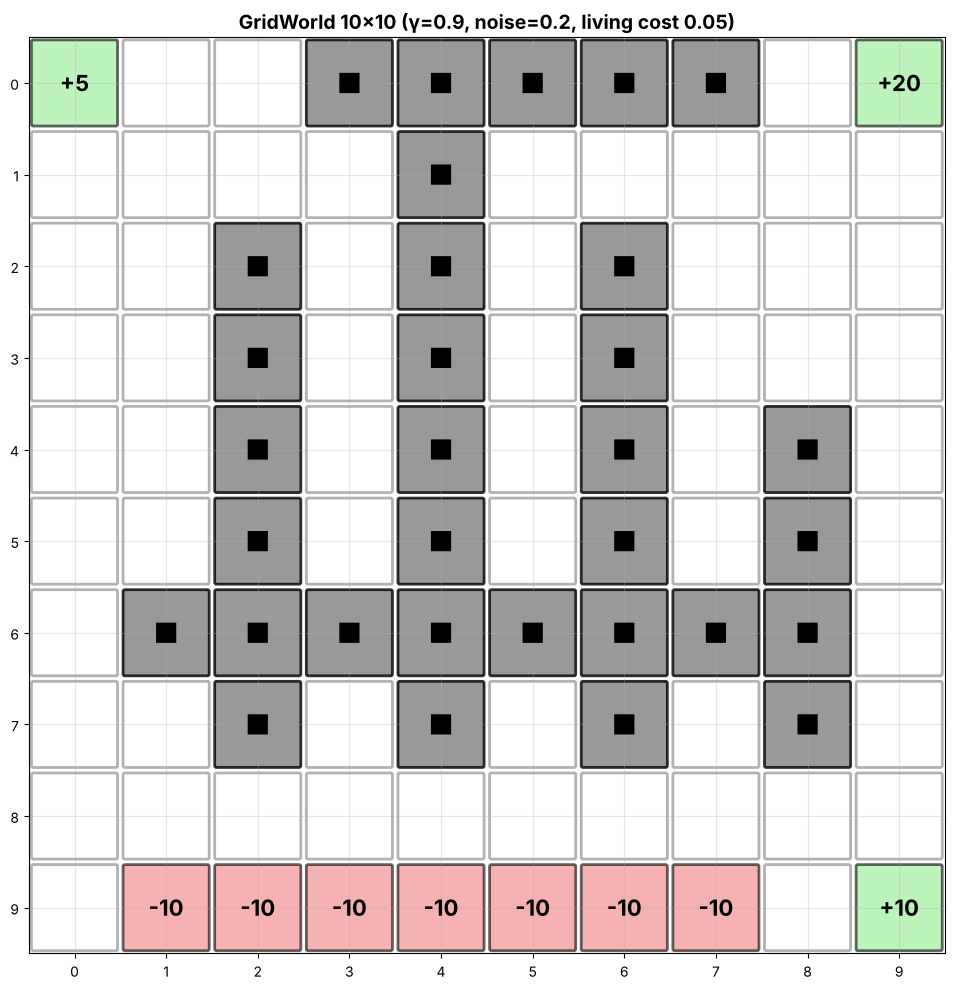

INFORMAÇÕES DO GRIDWORLD
Dimensões: 10 linhas x 10 colunas
Total de estados: 68
Paredes: 32
Estados terminais: 10
Fator de desconto (γ): 0.9
Ruído: 0.2
Living reward: -0.05
Ações disponíveis: ['N', 'S', 'L', 'O']

Paredes: [(0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 4), (2, 2), (2, 4), (2, 6), (3, 2), (3, 4), (3, 6), (4, 2), (4, 4), (4, 6), (4, 8), (5, 2), (5, 4), (5, 6), (5, 8), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6), (6, 7), (6, 8), (7, 2), (7, 4), (7, 6), (7, 8)]

Estados terminais:
  (0, 0): reward = 5.0
  (0, 9): reward = 20.0
  (9, 1): reward = -10.0
  (9, 2): reward = -10.0
  (9, 3): reward = -10.0
  (9, 4): reward = -10.0
  (9, 5): reward = -10.0
  (9, 6): reward = -10.0
  (9, 7): reward = -10.0
  (9, 9): reward = 10.0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Módulos do projeto
from environment import GridWorld, create_custom_gridworld, print_gridworld_info
from algorithms import td_zero_prediction, sarsa, q_learning, expected_sarsa, get_greedy_policy
from visualization import visualize_gridworld, visualize_q_values, plot_learning_curves, plot_value_heatmap, compare_algorithms
from compare_q_values import compare_q_values_by_states, find_most_divergent_states

# ---------- Parâmetros do enunciado ----------
ROWS, COLS   = 10, 10
LIVING_COST  = 0.05        # recompensa por passo = -0.05
NEG_TERMINAL = -10.0       # recompensa dos 7 terminais da linha 9
GAMMA, NOISE = 0.9, 0.2    # valores de referência (seções 5 a 9)

# ---------- Hiperparâmetros de treino (aprovados) ----------
N_EPISODES, N_SEEDS = 5000, 5
ALPHA, EPSILON      = 0.1, 0.1     # ε constante: os módulos não têm decaimento
WINDOW              = 250          # janela da média móvel (250 em vez de 100: os retornos por episódio são muito ruidosos)
FIGSIZE             = (10, 10)     # o padrão do visualize_gridworld seria 20x20 para um grid 10x10


def build_gridworld(gamma=GAMMA, noise=NOISE):
    """Monta o grid 10x10 do enunciado. Coordenadas (linha, coluna); a linha 0 fica no topo."""
    walls = set()
    walls |= {(0, c) for c in range(3, 8)}     # 8.  linha 0, colunas 3 a 7
    walls |= {(6, c) for c in range(1, 8)}     # 4.  linha 6, colunas 1 a 7
    walls |= {(r, 2) for r in range(2, 10)}    # 9.  coluna 2, linhas 2 a 9 (menos (8,2): passagem)
    walls |= {(r, 4) for r in range(1, 8)}     # 10. coluna 4, linhas 1 a 7
    walls |= {(r, 6) for r in range(2, 10)}    # 11. coluna 6, linhas 2 a 9 (menos (8,6): passagem)
    walls |= {(r, 8) for r in range(4, 8)}     # 12. coluna 8, linhas 4 a 7

    terminals = {(9, c): NEG_TERMINAL for c in range(1, 8)}   # 3. sete terminais na linha 9, colunas 1 a 7
    terminals[(9, 9)] = 10.0                                  # 5. terminal +10
    terminals[(0, 9)] = 20.0                                  # 6. terminal +20
    terminals[(0, 0)] = 5.0                                   # 7. terminal +5

    walls -= set(terminals)   # (9,2) e (9,6): o terminal prevalece (premissa 4)
    walls -= {(8, 2), (8, 6)} # passagens na linha 8 (pedido posterior): ligam a região inferior à esquerda e à direita (premissa 5)
    return create_custom_gridworld(ROWS, COLS, sorted(walls), terminals,
                                   gamma=gamma, noise=noise, living_reward=-LIVING_COST)


gw_ref = build_gridworld()
visualize_gridworld(gw_ref, title="GridWorld 10x10 (γ=0.9, noise=0.2, living cost 0.05)", figsize=FIGSIZE)
print_gridworld_info(gw_ref)

**Leitura da topologia.** Com as passagens em (8,2) e (8,6), o grid tem **uma única região conexa** de 58 células livres:

- **Esquerda** (24 células): leva ao terminal **+5**.
- **Direita** (27 células): leva a **+20** e **+10**. Aqui estão as melhores recompensas.
- **Região inferior** (5 células: (7,3), (7,5), (8,3), (8,4), (8,5)): agora liga as duas outras pela **linha 8**, passando por (8,2) e (8,6).

A linha 8 é o único caminho entre a esquerda e a direita, e ela corre **colada à fileira de terminais de −10** (linha 9). Um escorregão lateral ali pode ser fatal, e é isso que deve tornar o noise relevante nas análises das seções 10 e 11.

In [2]:
BOLSAO = [(7, 3), (7, 5), (8, 3), (8, 4), (8, 5)]   # as 5 células da região inferior (antes fechada, agora ligada pela linha 8)

## 3. Gabarito exato (Value Iteration)

Os módulos não trazem uma solução exata. Como o ambiente é conhecido, `gw.get_all_transitions(s, a)` devolve a lista `(probabilidade, próximo_estado, recompensa)`, e com ela dá para calcular a solução ótima. O gabarito serve para **avaliar** o que os algoritmos aprenderam, e não para treiná-los.

- `value_iteration` aplica $V(s) \leftarrow \max_a \sum_{s'} P(s'|s,a)\,[R + \gamma V(s')]$ até convergir e devolve $V^*$ e $Q^*$.
- `policy_evaluation` calcula o $V^\pi$ **exato** de uma política fixa (a mesma recursão, sem o máximo). É a referência do TD(0).
- `avaliar_politica` mede, para a política gulosa de uma tabela Q: **% de ações ótimas** (uma ação conta como ótima se $Q^*(s,a)$ estiver a menos de 1e-6 do máximo, o que trata empates) e a **perda de valor** média $\overline{V^* - V^\pi}$.
- `mudancas_reais` (usada nas seções 10 e 11) lista as células em que **todas** as ações ótimas da configuração de referência perdem mais de 0.05 de valor na nova configuração. Isso separa mudança real de política de empate entre ações.

In [3]:
_CACHE_T, _CACHE_G = {}, {}


def modelo_de_transicao(gw):
    """{(s, a): [(prob, s', recompensa), ...]} via gw.get_all_transitions (depende do layout e do noise, não de γ)."""
    chave = gw.noise
    if chave not in _CACHE_T:
        _CACHE_T[chave] = {(s, a): gw.get_all_transitions(s, a)
                           for s in gw.states if not gw.is_terminal(s) for a in gw.actions}
    return _CACHE_T[chave]


def valor_acao(T, V, s, a, gamma):
    return sum(p * (r + gamma * V[s2]) for p, s2, r in T[(s, a)])


def value_iteration(gw, gamma, tol=1e-10):
    """Retorna (V*, Q*) exatos. V* é um dict {estado: valor}; Q* é {estado: {ação: valor}}."""
    T = modelo_de_transicao(gw)
    livres = [s for s in gw.states if not gw.is_terminal(s)]
    V = {s: 0.0 for s in gw.states}                        # V(terminal) = 0
    while True:
        delta = 0.0
        for s in livres:
            novo = max(valor_acao(T, V, s, a, gamma) for a in gw.actions)
            delta = max(delta, abs(novo - V[s]))
            V[s] = novo
        if delta < tol:
            break
    Q = {s: {a: valor_acao(T, V, s, a, gamma) for a in gw.actions} for s in livres}
    return V, Q


def gabarito(gw, gamma):
    """value_iteration com cache por (noise, γ)."""
    chave = (gw.noise, gamma)
    if chave not in _CACHE_G:
        _CACHE_G[chave] = value_iteration(gw, gamma)
    return _CACHE_G[chave]


def policy_evaluation(gw, policy, gamma, tol=1e-10):
    """V^π exato de uma política determinística {estado: ação}."""
    T = modelo_de_transicao(gw)
    V = {s: 0.0 for s in gw.states}
    while True:
        delta = 0.0
        for s in policy:
            novo = valor_acao(T, V, s, policy[s], gamma)
            delta = max(delta, abs(novo - V[s]))
            V[s] = novo
        if delta < tol:
            break
    return V


def avaliar_politica(gw, Q, gamma, tol=1e-6):
    """Compara a política gulosa de Q com o gabarito: % de ações ótimas e perda média de valor."""
    V_star, Q_star = gabarito(gw, gamma)
    pol = get_greedy_policy(Q, gw)
    otimas = [Q_star[s][pol[s]] >= max(Q_star[s].values()) - tol for s in pol]
    V_pi = policy_evaluation(gw, pol, gamma)
    perda = np.mean([V_star[s] - V_pi[s] for s in pol])
    return {'pct_otimas': 100 * np.mean(otimas), 'perda_valor': perda}


def mudancas_reais(cfg, ref, tol=0.05):
    """Células onde TODAS as ações ótimas da referência perdem mais de tol de valor na configuração cfg."""
    _, Q_cfg = gabarito(cfg['gw'], cfg['gamma'])
    _, Q_ref = gabarito(ref['gw'], ref['gamma'])
    saida = []
    for s in Q_cfg:
        otimas_ref = [a for a, q in Q_ref[s].items() if q >= max(Q_ref[s].values()) - 1e-6]
        perda = max(Q_cfg[s].values()) - max(Q_cfg[s][a] for a in otimas_ref)
        if perda > tol:
            saida.append((s, round(perda, 2)))
    return saida


V_star_ref, Q_star_ref = gabarito(gw_ref, GAMMA)
print("V* nas 5 células da região inferior:", {s: round(V_star_ref[s], 3) for s in BOLSAO}, "| valor de nunca terminar:", -LIVING_COST / (1 - GAMMA))
print("V* médio nos estados livres:", round(np.mean([V_star_ref[s] for s in Q_star_ref]), 3))

V* nas 5 células da região inferior: {(7, 3): -0.209, (7, 5): 1.143, (8, 3): -0.169, (8, 4): 0.208, (8, 5): 1.371} | valor de nunca terminar: -0.5000000000000001
V* médio nos estados livres: 6.531


## 4. Funções auxiliares de treino e exibição

Cada algoritmo (`sarsa`, `q_learning`, `expected_sarsa`) devolve `(Q, recompensas_por_episódio)`. Elas **não têm parâmetro de seed**, e o módulo usa o gerador global do NumPy. Por isso `treinar` chama `np.random.seed(seed)` antes de cada execução, o que torna os resultados reprodutíveis.

- `treinar` roda **5 seeds** e guarda a **média das tabelas Q** (dela sai a política) e a **média das curvas de recompensa** (é o que vai para `plot_learning_curves`, que desenha uma curva por rótulo).
- O **gamma é passado explicitamente** a cada algoritmo, porque as funções de controle usam o argumento `gamma` e **não** `gw.gamma`.
- `mostrar` desenha as curvas de treino e o gridworld com V(s) = max_a Q(s,a) e a política gulosa, e imprime as métricas contra o gabarito.

In [4]:
def treinar(algoritmo, gw, gamma, n_seeds=N_SEEDS):
    """Treina n_seeds execuções independentes. Retorna a média das Q, a média das curvas e o contexto."""
    Qs, curvas = [], []
    for seed in range(n_seeds):
        np.random.seed(seed)                                   # seed global usada pelos módulos
        Q, recompensas = algoritmo(gw, n_episodes=N_EPISODES, alpha=ALPHA, gamma=gamma, epsilon=EPSILON)
        Qs.append(Q)
        curvas.append(recompensas)
    return {'Q': np.mean(Qs, axis=0), 'recompensas': np.mean(curvas, axis=0), 'curvas': np.array(curvas), 'gw': gw, 'gamma': gamma}


def valores_de_Q(Q, gw):
    """V(s) = max_a Q(s,a) como dict {estado: valor}, o formato que visualize_gridworld espera."""
    return {s: float(np.max(Q[s[0] * gw.cols + s[1]])) for s in gw.states if not gw.is_terminal(s)}


def mostrar(res, nome):
    """Curvas de treino + gridworld com valores e política + métricas contra o gabarito."""
    gw = res['gw']
    plot_learning_curves({nome: res['recompensas']}, window=WINDOW,
                         title=f"{nome}: curvas de treinamento (média de {N_SEEDS} seeds)")
    V, pi = valores_de_Q(res['Q'], gw), get_greedy_policy(res['Q'], gw)
    visualize_gridworld(gw, values=V, policy=pi, figsize=FIGSIZE,
                        title=f"{nome}: V(s) e política ótima aprendida (γ={res['gamma']}, noise={gw.noise})")
    m = avaliar_politica(gw, res['Q'], res['gamma'])
    print(f"{nome}: {m['pct_otimas']:.0f}% das ações são ótimas | perda média de valor (V* − Vπ) = {m['perda_valor']:.3f} | "
          f"retorno médio nos últimos 500 episódios = {np.mean(res['recompensas'][-500:]):.2f}")

### Teste curto (antes dos treinos completos)

Os módulos não limitam os passos por episódio. Se alguma política aprendida ficar presa (por exemplo, batendo numa parede para sempre), o episódio só acaba por **exploração (ε) ou escorregão**, e pode ficar longo. Esta célula treina cada algoritmo por 500 episódios e **cronometra**. O pior episódio dá uma ideia do custo: cada passo custa −0.05, e a recompensa do terminal entra no total.

In [5]:
import time
for nome, alg in [('SARSA', sarsa), ('Q-Learning', q_learning), ('Expected SARSA', expected_sarsa)]:
    np.random.seed(0)
    t0 = time.time()
    _, r = alg(gw_ref, n_episodes=500, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON)
    dt = time.time() - t0
    print(f"{nome:>15}: 500 episódios em {dt:4.1f}s | pior episódio: {min(r):7.1f} "
          f"| estimativa para 5000 ep × {N_SEEDS} seeds: {dt * 10 * N_SEEDS / 60:.1f} min")

          SARSA: 500 episódios em  0.1s | pior episódio:   -20.8 | estimativa para 5000 ep × 5 seeds: 0.0 min
     Q-Learning: 500 episódios em  0.0s | pior episódio:   -14.7 | estimativa para 5000 ep × 5 seeds: 0.0 min


 Expected SARSA: 500 episódios em  0.2s | pior episódio:   -53.9 | estimativa para 5000 ep × 5 seeds: 0.1 min


## 5. SARSA (on-policy)

**State–Action–Reward–State–Action.** Aprende $Q^\pi$ da **própria política que está seguindo** (ε-greedy) e usa no alvo a ação $A_{t+1}$ que **será realmente executada**:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha\big[R_{t+1} + \gamma\, Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t)\big]$$

```
Para cada episódio:
  Inicializar S; escolher A de S usando ε-greedy(Q)
  Para cada passo:
    Executar A, observar R, S'
    Escolher A' de S' usando ε-greedy(Q)
    Q(S,A) ← Q(S,A) + α [ R + γ Q(S',A') − Q(S,A) ]
    S ← S'; A ← A'
  até S ser terminal
```

**Características (do resumo teórico):** os valores já **embutem a exploração**, o que dá um comportamento mais **cauteloso** e seguro. Converge para $Q^\pi$ da política seguida. Custo $O(1)$ por atualização.

**O que esperar aqui:** com ε = 0.1 o agente às vezes executa uma ação aleatória. A linha 9 é uma fileira de terminais de −10, então o SARSA tende a **se afastar** dela (analogia com o *Cliff Walking* do resumo).

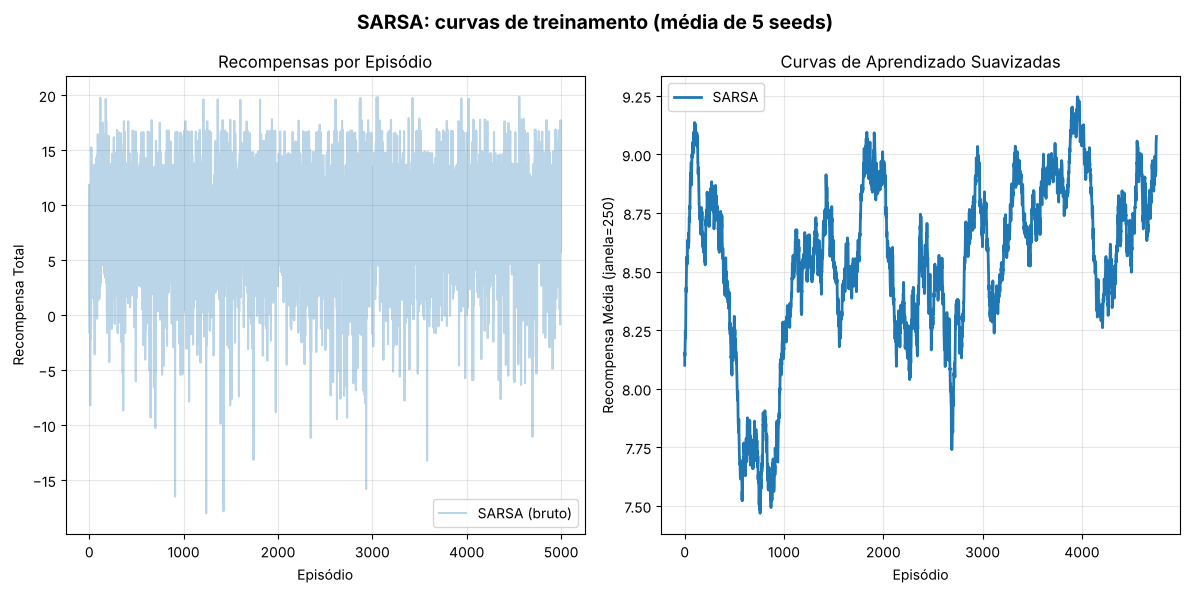

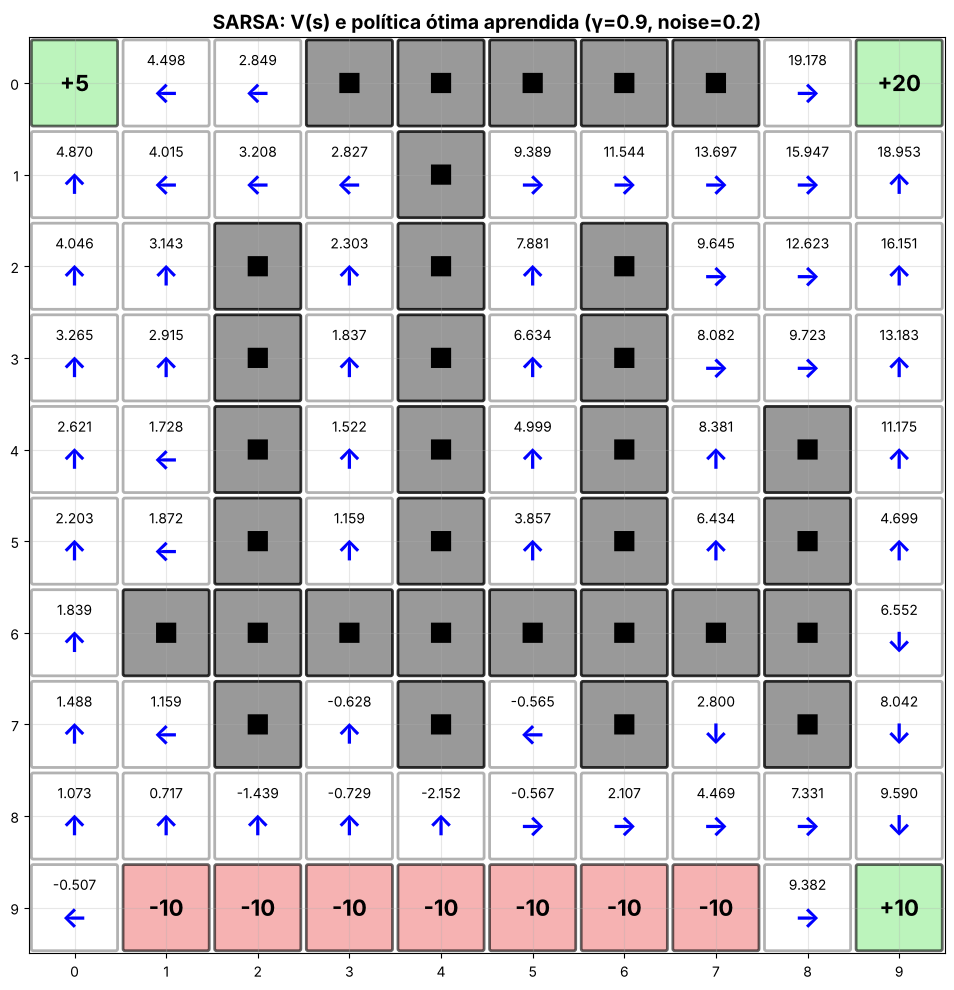

SARSA: 84% das ações são ótimas | perda média de valor (V* − Vπ) = 0.103 | retorno médio nos últimos 500 episódios = 8.79


In [6]:
RES = {}
RES['SARSA'] = treinar(sarsa, gw_ref, GAMMA)
mostrar(RES['SARSA'], 'SARSA')

## 6. Q-Learning (off-policy)

Aprende a **política ótima independentemente da política de exploração**. O alvo usa o **máximo** de $Q$ no próximo estado, e não a ação que será de fato executada:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha\big[R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t)\big]$$

```
Para cada episódio:
  Inicializar S
  Para cada passo:
    Escolher A de S usando ε-greedy(Q)
    Executar A, observar R, S'
    Q(S,A) ← Q(S,A) + α [ R + γ max_a Q(S',a) − Q(S,A) ]
    S ← S'
  até S ser terminal
```

**Características:** *off-policy* (política alvo ≠ política de comportamento), mais **agressivo** na busca por otimalidade. Converge para $Q^*$. Custo $O(\lvert A\rvert)$ por atualização.

**O que esperar aqui:** como o alvo ignora a exploração, o Q-Learning aprende o **melhor caminho possível**, mesmo que passe perto dos terminais de −10. Em compensação, durante o treino ele cai neles com mais frequência por causa das ações aleatórias.

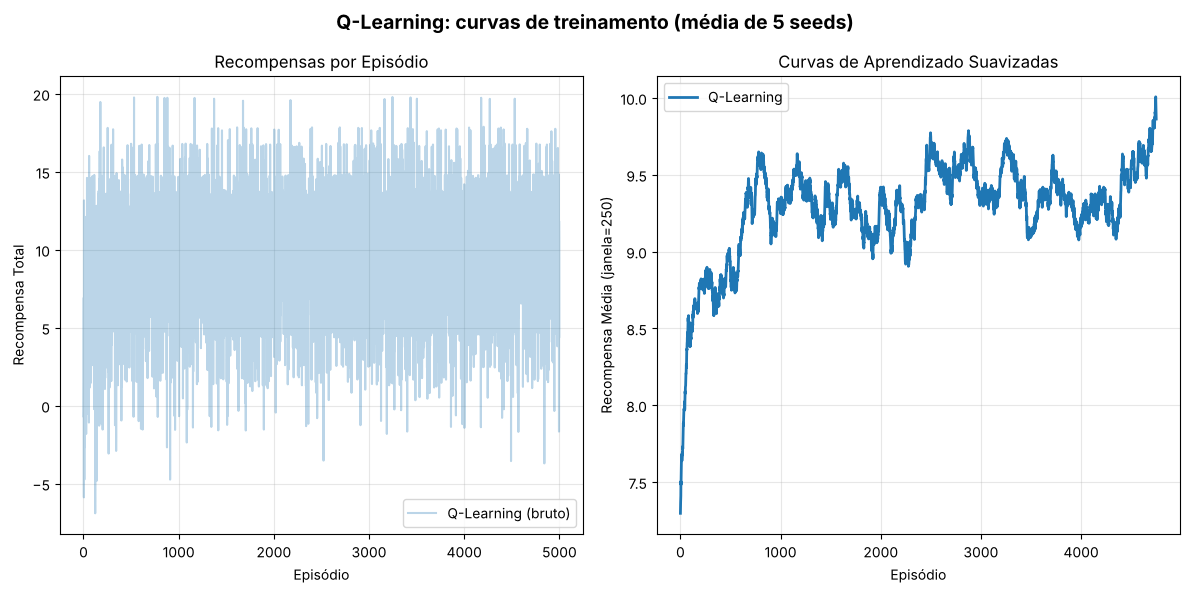

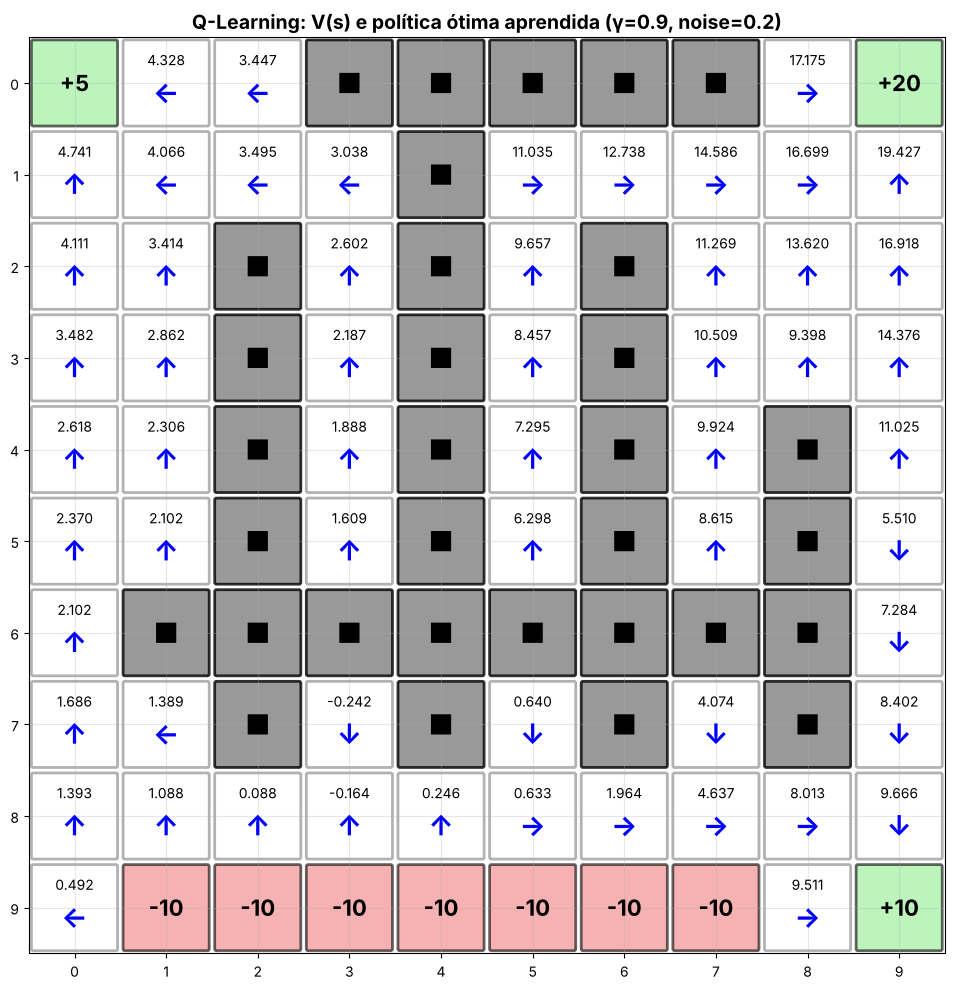

Q-Learning: 97% das ações são ótimas | perda média de valor (V* − Vπ) = 0.119 | retorno médio nos últimos 500 episódios = 9.71


In [7]:
RES['Q-Learning'] = treinar(q_learning, gw_ref, GAMMA)
mostrar(RES['Q-Learning'], 'Q-Learning')

## 7. Expected SARSA

Em vez de amostrar $A_{t+1}$, usa a **esperança** de $Q$ sob a política ε-greedy no próximo estado:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha\Big[R_{t+1} + \gamma \sum_a \pi(a \mid S_{t+1})\, Q(S_{t+1}, a) - Q(S_t, A_t)\Big]$$

```
Para cada episódio:
  Inicializar S
  Para cada passo:
    Escolher A de S usando ε-greedy(Q); executar A, observar R, S'
    V_esperado ← Σ_a π(a|S') · Q(S',a)        # π = ε-greedy
    Q(S,A) ← Q(S,A) + α [ R + γ V_esperado − Q(S,A) ]
    S ← S'
  até S ser terminal
```

**Características:** **elimina a variância** da escolha de $A_{t+1}$, o que costuma dar mais estabilidade, ao custo de $O(\lvert A\rvert)$ por atualização. É um meio-termo entre SARSA e Q-Learning.

**O que esperar aqui:** curvas mais suaves e valores entre os do SARSA e os do Q-Learning.

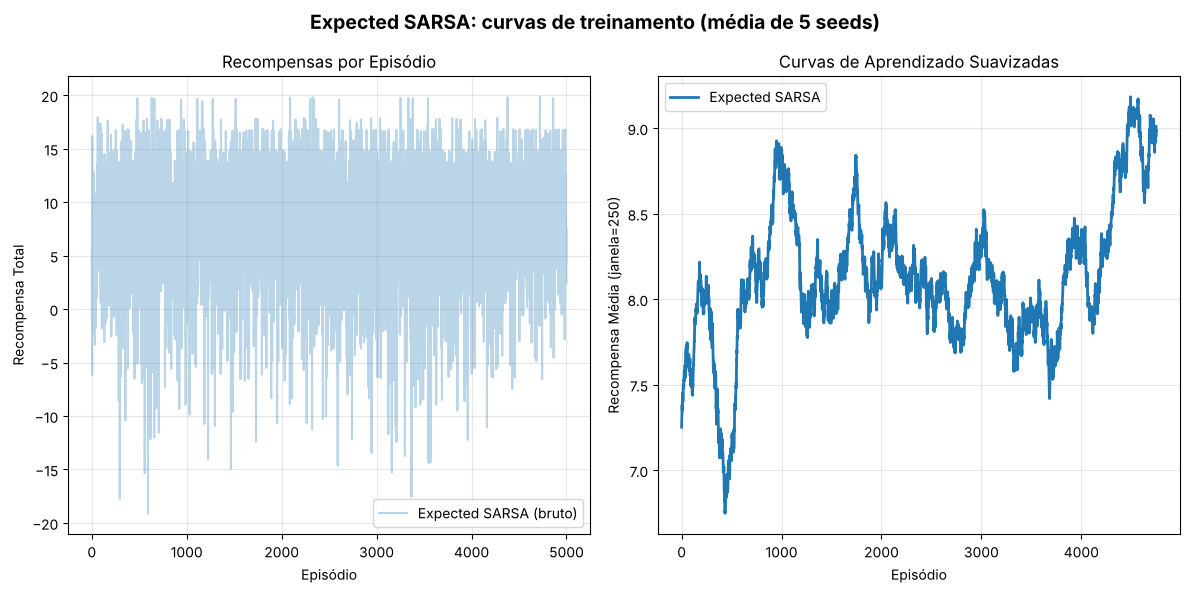

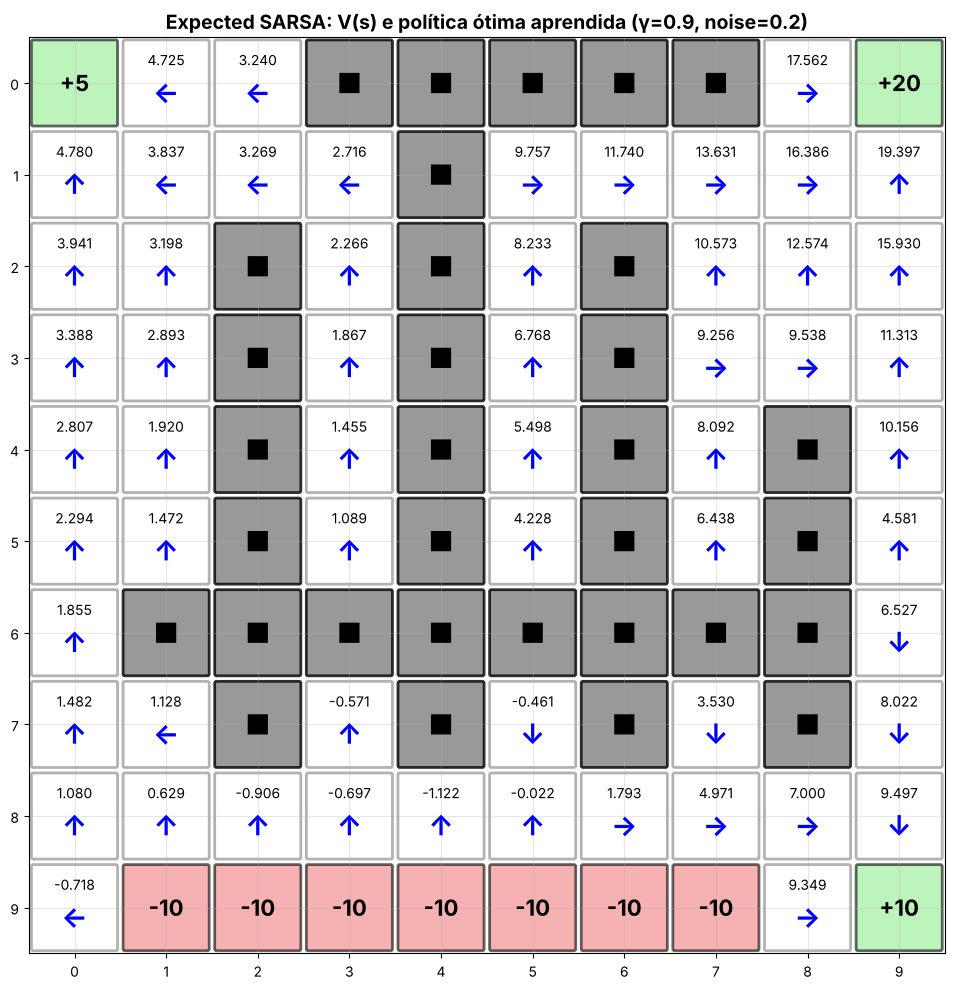

Expected SARSA: 91% das ações são ótimas | perda média de valor (V* − Vπ) = 0.099 | retorno médio nos últimos 500 episódios = 8.99


In [8]:
RES['Expected SARSA'] = treinar(expected_sarsa, gw_ref, GAMMA)
mostrar(RES['Expected SARSA'], 'Expected SARSA')

## 8. Comparação dos três algoritmos

| Característica | SARSA | Q-Learning | Expected SARSA |
|---|---|---|---|
| Tipo | on-policy | off-policy | ambos |
| Alvo da atualização | $Q(S',A')$ | $\max_a Q(S',a)$ | $\mathbb{E}_\pi[Q(S',a)]$ |
| Comportamento | cauteloso | otimista/agressivo | balanceado |
| Exploração afeta os valores | sim | não | ponderada |
| Custo por atualização | $O(1)$ | $O(\lvert A\rvert)$ | $O(\lvert A\rvert)$ |

Abaixo: curvas sobrepostas, a tabela de métricas contra o gabarito e as funções de `compare_q_values.py`, que apontam **os estados em que os algoritmos mais divergem**.

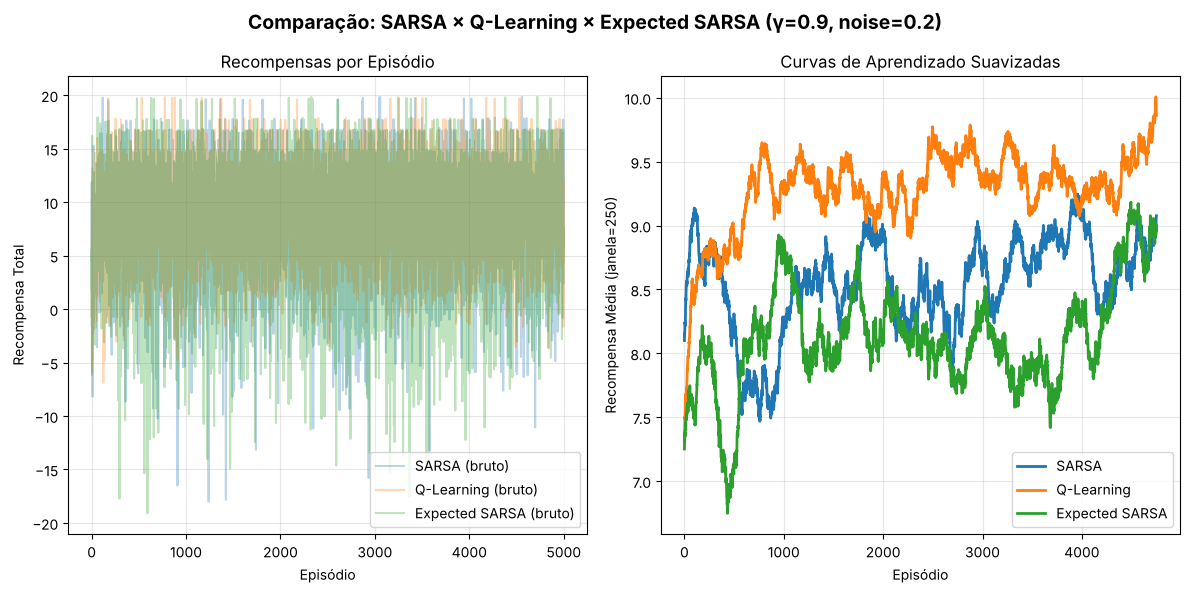

,% ações ótimas,perda de valor (V*−Vπ),retorno médio (últimos 500 ep.)
SARSA,84.483,0.103,8.789
Q-Learning,96.552,0.119,9.707
Expected SARSA,91.379,0.099,8.992


In [9]:
plot_learning_curves({n: r['recompensas'] for n, r in RES.items()}, window=WINDOW,
                     title=f"Comparação: SARSA × Q-Learning × Expected SARSA (γ={GAMMA}, noise={NOISE})")

linhas = {}
for n, r in RES.items():
    m = avaliar_politica(r['gw'], r['Q'], r['gamma'])
    linhas[n] = {'% ações ótimas': m['pct_otimas'], 'perda de valor (V*−Vπ)': m['perda_valor'],
                 'retorno médio (últimos 500 ep.)': np.mean(r['recompensas'][-500:])}
pd.DataFrame(linhas).T.round(3)

Estados com maior divergência de V(s) entre os algoritmos:
  (3, 9): Δ = 3.063
  (5, 5): Δ = 2.441
  (3, 7): Δ = 2.427
  (8, 4): Δ = 2.398
  (4, 5): Δ = 2.296

COMPARAÇÃO DE Q-VALUES ENTRE ALGORITMOS
Algoritmos analisados: ['SARSA', 'Q-Learning', 'Expected SARSA']
Número de estados: 5
Estados: [(3, 9), (5, 5), (3, 7), (8, 4), (4, 5)]

────────────────────────────────────────────────────────────────────────────────
VALORES MÁXIMOS POR ESTADO: V(s) = max_a Q(s,a)
────────────────────────────────────────────────────────────────────────────────

Estado         SARSA               Q-Learning          Expected SARSA      Δmax
────────────────────────────────────────────────────────────────────────────────
(3, 9)         13.1832             14.3756             11.3127             3.0629  
(5, 5)         3.8570              6.2982              4.2281              2.4412  
(3, 7)         8.0818              10.5093             9.2565              2.4275  
(8, 4)         -2.1519             0.24

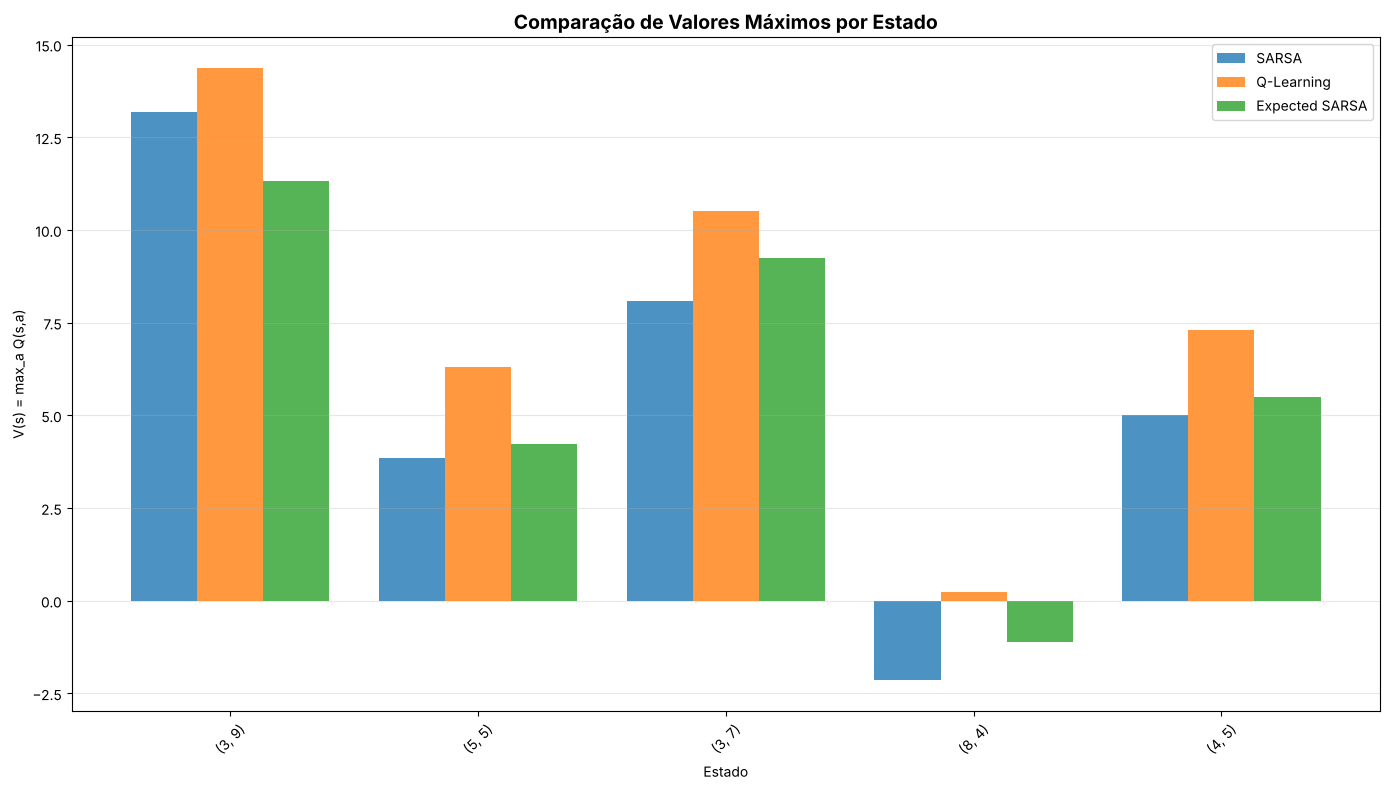


✅ Análise completa!

DataFrame retornado com 5 linhas
Para acessar: df = compare_q_values_by_states(...)


In [10]:
Q_dict = {n: r['Q'] for n, r in RES.items()}
divergentes = find_most_divergent_states(Q_dict, gw_ref, n_states=5)      # (estado, divergência max−min de V)
print("Estados com maior divergência de V(s) entre os algoritmos:")
for s, d in divergentes:
    print(f"  {s}: Δ = {d:.3f}")

df_div = compare_q_values_by_states(Q_dict, gw_ref, selected_states=[s for s, _ in divergentes],
                                    show_actions=False, show_differences=True, plot_comparison=True)

In [11]:
compare_algorithms(Q_dict, gw_ref)    # tabela completa de V(s) = max_a Q(s,a) por estado e estatísticas resumidas

COMPARAÇÃO DE VALORES APRENDIDOS

Estado         SARSA               Q-Learning          Expected SARSA      
--------------------------------------------------------------------------------
(0, 1)         4.4985              4.3284              4.7251              
(0, 2)         2.8494              3.4471              3.2400              
(0, 8)         19.1784             17.1750             17.5616             
(1, 0)         4.8703              4.7413              4.7801              
(1, 1)         4.0146              4.0662              3.8368              
(1, 2)         3.2081              3.4946              3.2686              
(1, 3)         2.8272              3.0378              2.7159              
(1, 5)         9.3893              11.0347             9.7573              
(1, 6)         11.5441             12.7385             11.7401             
(1, 7)         13.6970             14.5863             13.6307             
(1, 8)         15.9468             16.6989       

### Diagnóstico: o quanto dá para confiar nas diferenças

Duas verificações antes de comparar os algoritmos:

1. **Linha de base:** uma política trivial "sempre N" (o desempate do `argmax` quando Q é zero). Se ela já acertasse quase tudo, a % de ações ótimas dos algoritmos não diria nada.
2. **Dispersão entre seeds:** o retorno médio dos últimos 500 episódios, seed por seed. Com só 5 seeds, uma diferença entre algoritmos só merece atenção se for bem maior que essa dispersão.

Lembrete: o retorno por episódio mistura qualidade da política com **sorte do estado inicial** (sorteado entre as 58 células livres, com valores de V* que vão de ≈ −0,2 a ≈ 19), por isso é uma medida ruidosa.

In [12]:
# (i) Linha de base: Q = 0 em todo lugar => argmax cai na ação 0 ('N') em todos os estados
base = avaliar_politica(gw_ref, np.zeros((gw_ref.rows * gw_ref.cols, 4)), GAMMA)
print(f"Política trivial 'sempre N': {base['pct_otimas']:.0f}% de ações ótimas | perda de valor = {base['perda_valor']:.3f}")

# (ii) Retorno médio dos últimos 500 episódios, por seed
por_seed = {n: r['curvas'][:, -500:].mean(axis=1) for n, r in RES.items()}
tab = pd.DataFrame({n: {**{f'seed {k}': v for k, v in enumerate(vals)}, 'média': vals.mean(), 'desvio entre seeds': vals.std()}
                    for n, vals in por_seed.items()})
tab.round(2)

Política trivial 'sempre N': 64% de ações ótimas | perda de valor = 3.603


,SARSA,Q-Learning,Expected SARSA
seed 0,8.77,9.55,8.94
seed 1,9.53,9.77,9.84
seed 2,9.09,9.76,8.86
seed 3,8.34,10.41,9.12
seed 4,8.22,9.05,8.19
média,8.79,9.71,8.99
desvio entre seeds,0.48,0.44,0.53


## 9. TD(0): avaliação de uma política proposta

**Predição** (não controle): dada uma política fixa $\pi$, estimar $V^\pi$ com

$$V(S_t) \leftarrow V(S_t) + \alpha\big[R_{t+1} + \gamma V(S_{t+1}) - V(S_t)\big], \qquad \delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$$

O termo entre colchetes é o **erro TD** $\delta_t$. Diferente do Monte Carlo (que espera o retorno real $G_t$ no fim do episódio), o TD(0) atualiza **a cada passo** usando a estimativa de $V(S_{t+1})$ (*bootstrapping*): menor variância, com algum viés. Vale ainda $G_t - V(S_t) = \sum_k \gamma^k \delta_{t+k}$.

```
Para cada episódio:
  Inicializar S
  Para cada passo:
    A ← π(S); executar A, observar R, S'
    V(S) ← V(S) + α [ R + γ V(S') − V(S) ]
    S ← S'
  até S ser terminal                 # V(terminal) = 0
```

### Política proposta
Uso a **política gulosa do Q-Learning** da seção 6 (`get_greedy_policy`), sem alterações. `td_zero_prediction` não tem limite de passos, então uma política que **nunca termina** deixaria o programa em **laço infinito**. Antes de rodar, a célula abaixo confirma por simulação (`gw.sample_transition`) que isso não acontece: ela conta, para cada estado inicial, os episódios que **não terminam em 2.000 passos**. (Antes de abrir as passagens da linha 8 isso era um problema real; agora a checagem fica como salvaguarda.)

Ações na região inferior (política gulosa do Q-Learning): {(7, 3): 'S', (7, 5): 'S', (8, 3): 'N', (8, 4): 'N', (8, 5): 'L'}
Episódios que não terminam em 2.000 passos: nenhum


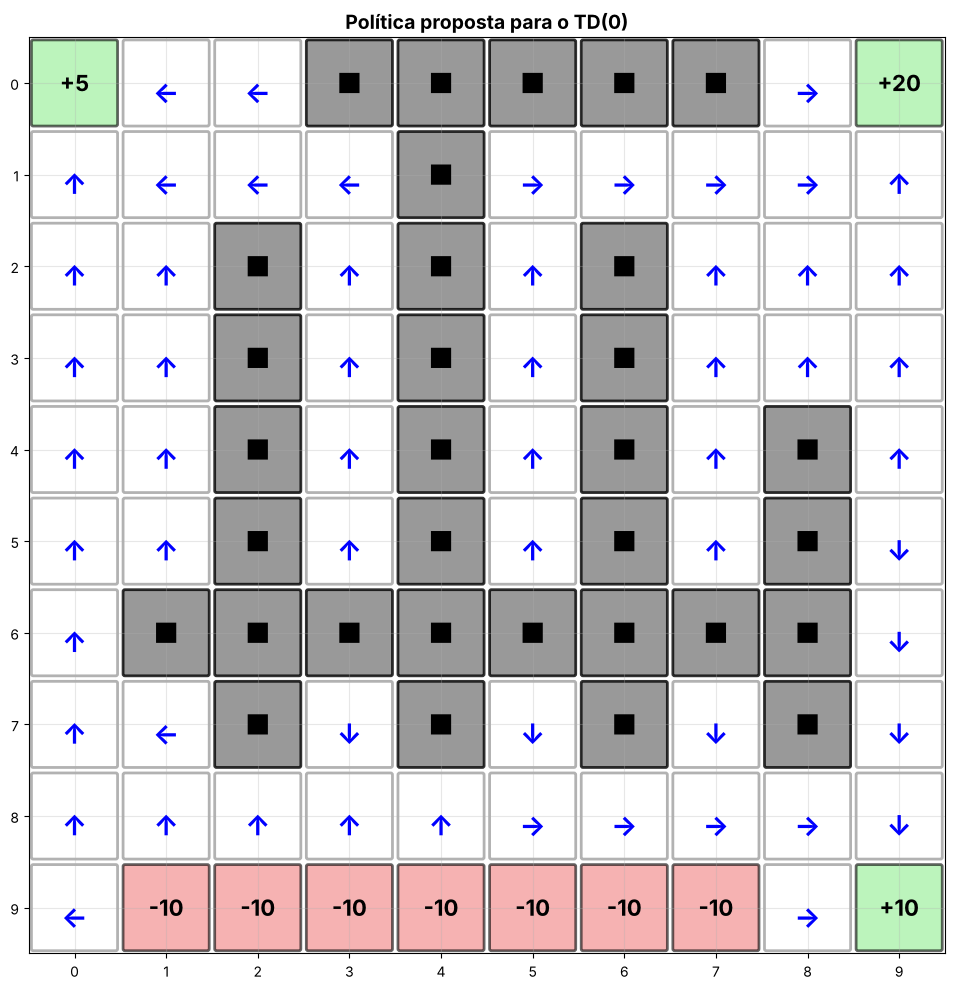

In [13]:
def episodios_que_nao_terminam(gw, policy, n_ep=50, max_passos=2000):
    """{estado_inicial: nº de episódios (de n_ep) que não chegaram a um terminal em max_passos passos}."""
    ruins = {}
    for s0 in policy:
        n = 0
        for _ in range(n_ep):
            s = s0
            for _ in range(max_passos):
                s, _r = gw.sample_transition(s, policy[s])
                if gw.is_terminal(s):
                    break
            else:
                n += 1
        if n:
            ruins[s0] = n
    return ruins


np.random.seed(123)
pi_td = get_greedy_policy(RES['Q-Learning']['Q'], gw_ref)
print("Ações na região inferior (política gulosa do Q-Learning):", {s: pi_td[s] for s in BOLSAO})
print("Episódios que não terminam em 2.000 passos:", episodios_que_nao_terminam(gw_ref, pi_td) or "nenhum")

visualize_gridworld(gw_ref, policy=pi_td, figsize=FIGSIZE, title="Política proposta para o TD(0)")


### TD(0) com 5 seeds e comparação com o V^π exato

`td_zero_prediction` usa `gw.gamma` (0.9) e devolve um dict `V`. Uso **α = 0.05 e 20.000 episódios**: com α constante, o TD(0) fica oscilando em torno do valor verdadeiro, e um α menor reduz esse ruído. Cada seed gera um `V`, e a figura mostra a média. O **V^π exato** (`policy_evaluation`) é a referência.

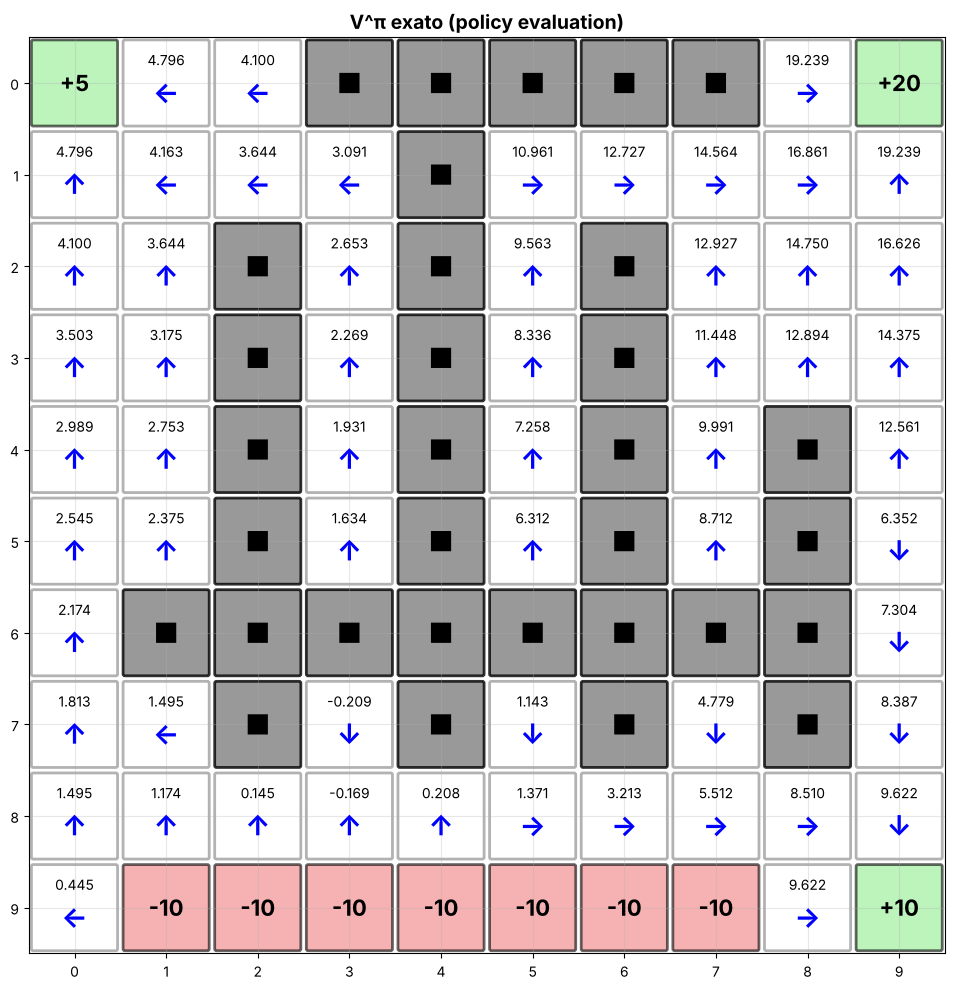

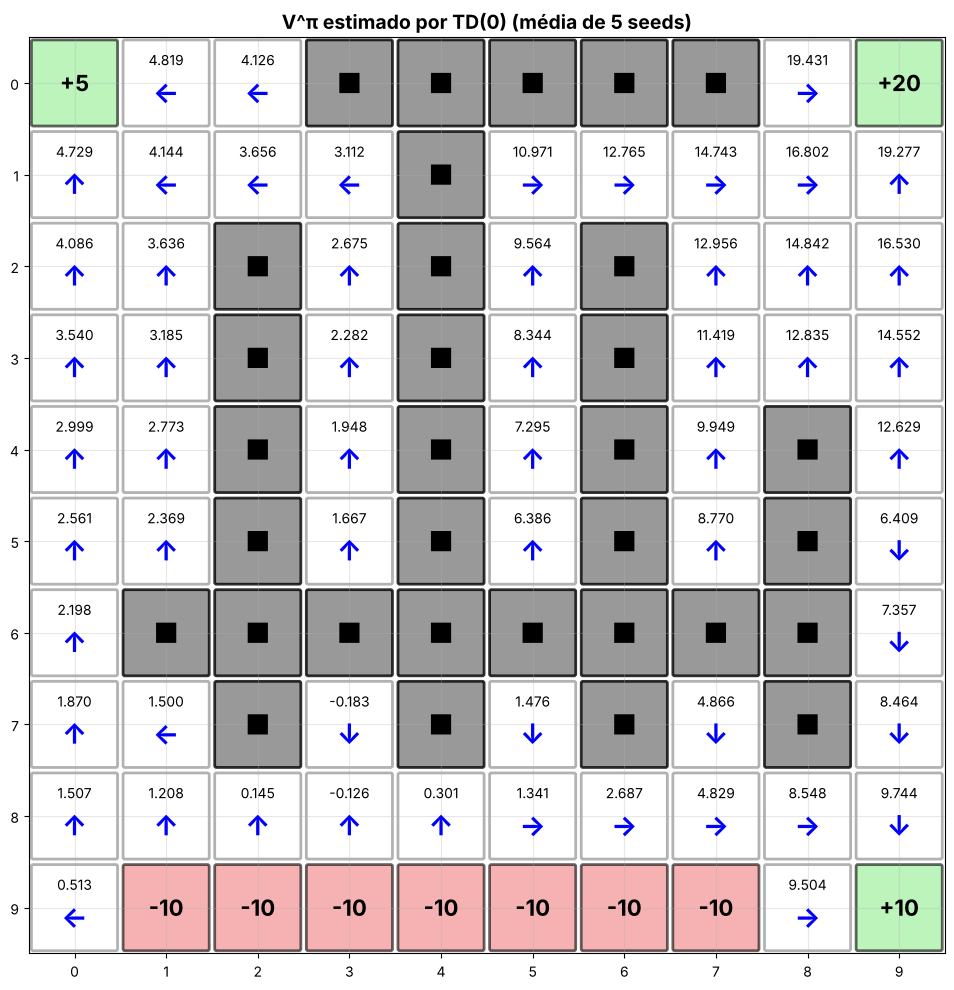

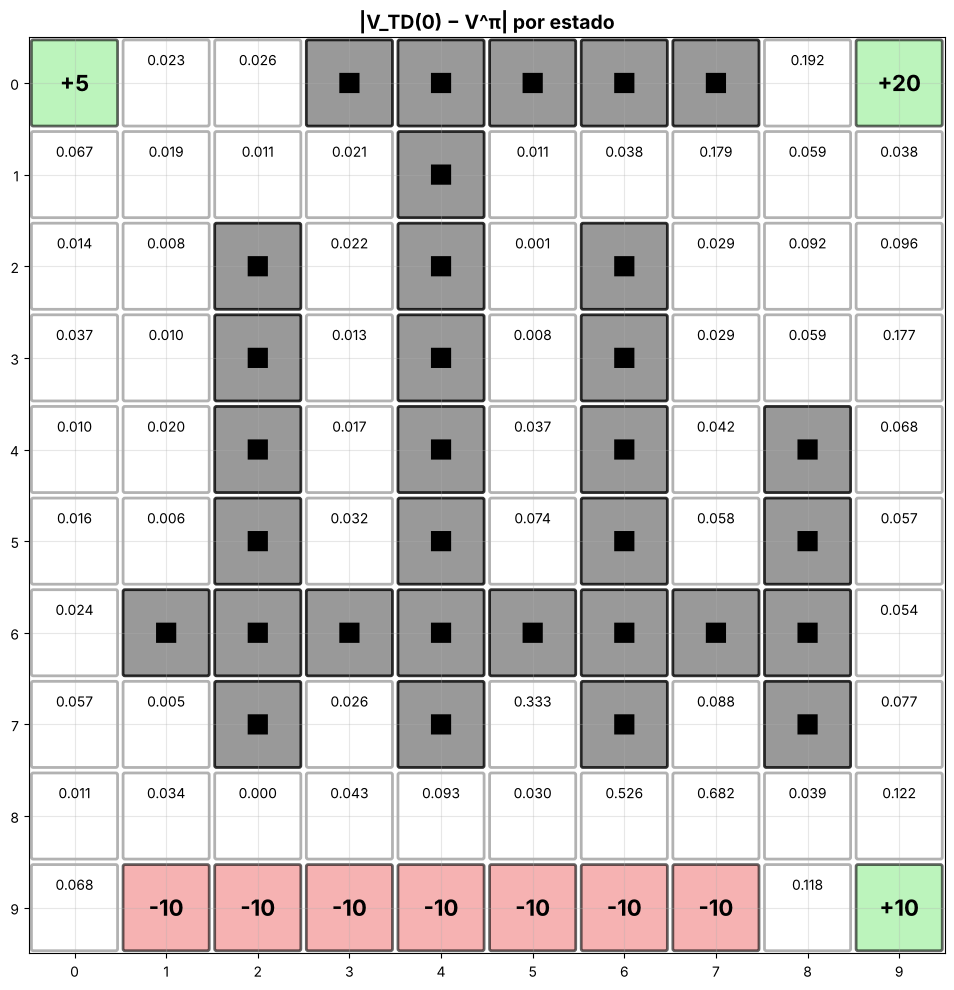

RMSE de cada seed: [0.345 0.278 0.369 0.225 0.228] | erro máximo da média das seeds: 0.682
V médio nos estados livres: π proposta (exato) = 6.412 | TD(0) = 6.423 | ótimo V* = 6.531


In [14]:
ALPHA_TD, N_TD = 0.05, 20000

V_runs = []
for seed in range(N_SEEDS):
    np.random.seed(seed)
    V_runs.append(td_zero_prediction(gw_ref, pi_td, n_episodes=N_TD, alpha=ALPHA_TD))
livres = list(pi_td)
V_td = {s: float(np.mean([V[s] for V in V_runs])) for s in livres}      # média das seeds
V_pi = policy_evaluation(gw_ref, pi_td, GAMMA)                          # V^π exato (gabarito do TD(0))
erro = {s: abs(V_td[s] - V_pi[s]) for s in livres}

visualize_gridworld(gw_ref, values=V_pi, policy=pi_td, figsize=FIGSIZE, title="V^π exato (policy evaluation)")
visualize_gridworld(gw_ref, values=V_td, policy=pi_td, figsize=FIGSIZE, title=f"V^π estimado por TD(0) (média de {N_SEEDS} seeds)")
visualize_gridworld(gw_ref, values=erro, figsize=FIGSIZE, title="|V_TD(0) − V^π| por estado")

rmse_por_seed = [np.sqrt(np.mean([(V[s] - V_pi[s]) ** 2 for s in livres])) for V in V_runs]
print("RMSE de cada seed:", np.round(rmse_por_seed, 3), "| erro máximo da média das seeds:", round(max(erro.values()), 3))
print(f"V médio nos estados livres: π proposta (exato) = {np.mean([V_pi[s] for s in livres]):.3f} | "
      f"TD(0) = {np.mean([V_td[s] for s in livres]):.3f} | ótimo V* = {np.mean([V_star_ref[s] for s in livres]):.3f}")

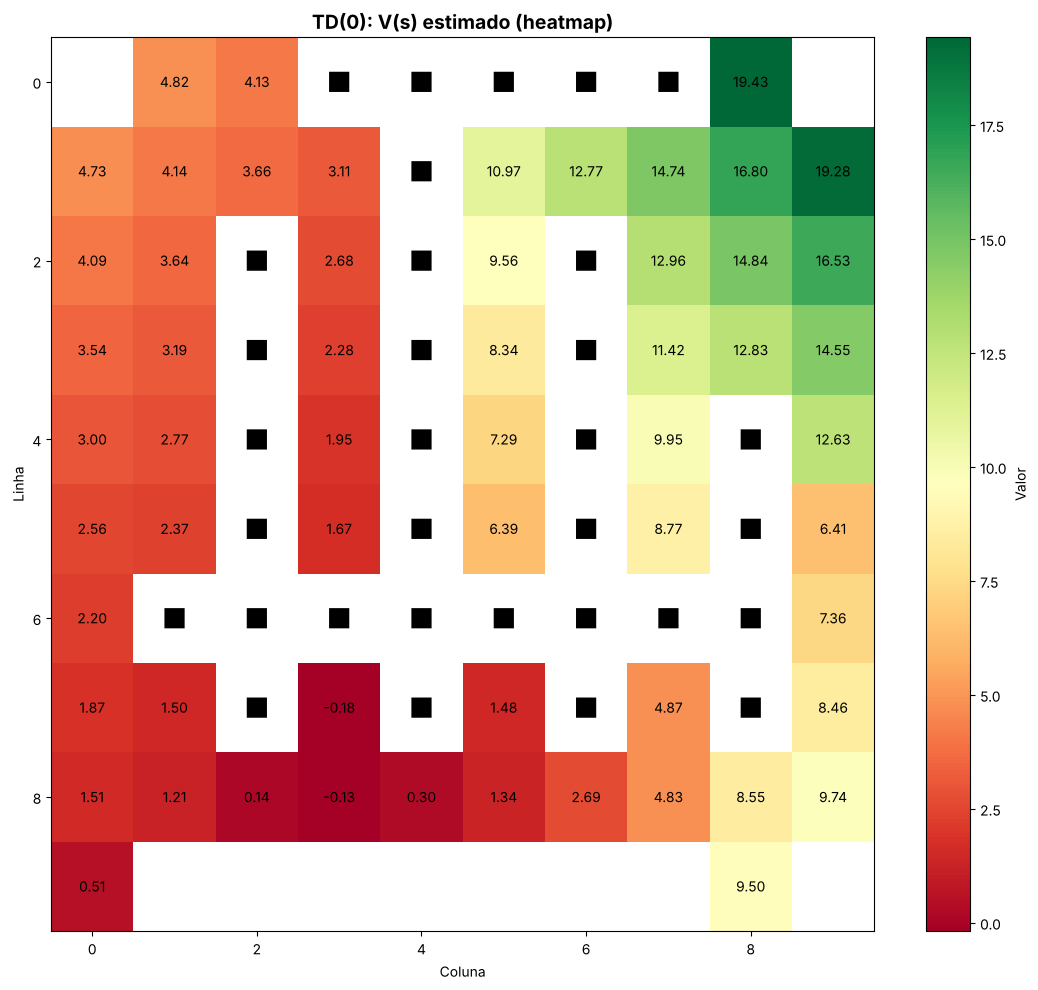

In [15]:
plot_value_heatmap(V_td, gw_ref, title="TD(0): V(s) estimado (heatmap)", figsize=(11, 10))

**Convergência.** `td_zero_prediction` só devolve o `V` final, então a convergência é medida repetindo a execução com números crescentes de episódios, e não por uma curva dentro de um treino. O gráfico mostra o RMSE contra o V^π exato (média ± desvio entre as 5 seeds).

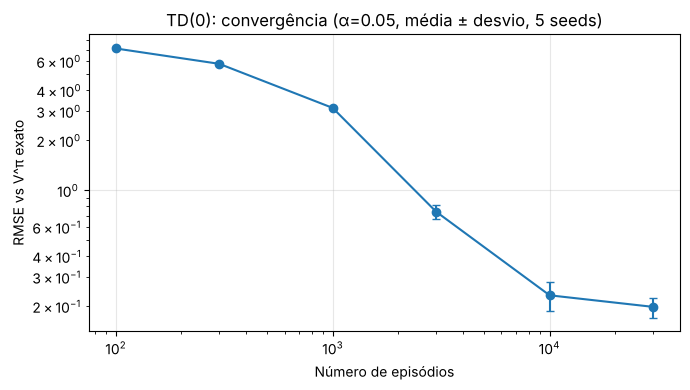

       RMSE médio  desvio
100         7.151   0.050
300         5.778   0.091
1000        3.133   0.027
3000        0.741   0.075
10000       0.233   0.046
30000       0.198   0.027


In [16]:
tamanhos = [100, 300, 1000, 3000, 10000, 30000]
rmse = np.zeros((N_SEEDS, len(tamanhos)))
for j, n in enumerate(tamanhos):
    for seed in range(N_SEEDS):
        np.random.seed(seed)
        V = td_zero_prediction(gw_ref, pi_td, n_episodes=n, alpha=ALPHA_TD)
        rmse[seed, j] = np.sqrt(np.mean([(V[s] - V_pi[s]) ** 2 for s in livres]))

plt.figure(figsize=(7, 4))
plt.errorbar(tamanhos, rmse.mean(0), yerr=rmse.std(0), marker='o', capsize=3)
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Número de episódios'); plt.ylabel('RMSE vs V^π exato')
plt.title(f'TD(0): convergência (α={ALPHA_TD}, média ± desvio, {N_SEEDS} seeds)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()
print(pd.DataFrame({'RMSE médio': rmse.mean(0), 'desvio': rmse.std(0)}, index=tamanhos).round(3))

## 10. Sensibilidade a γ (Q-Learning)

γ pondera quanto o agente "enxerga" o futuro. Uma recompensa +20 a $k$ passos de distância vale cerca de $20\,\gamma^k$ **hoje**, então com γ menor o terminal distante de +20 perde atratividade frente a terminais mais próximos (+10 e +5).

**Como é feito:** para cada γ cria-se um **grid novo** (`gamma=g`) e passa-se o **mesmo γ ao `q_learning`**, porque as funções de controle ignoram `gw.gamma`. O caso γ = 0.9 reaproveita o treino da seção 6, que usa a mesma configuração e as mesmas seeds. Noise fixo em 0.2.

**Hipótese:** com γ menor, algumas células passam a preferir terminais próximos de valor menor, e V(s) cai em todo o grid. Abaixo de cada figura de política, `mudancas_reais` lista as células em que a ação ótima exata da referência (γ = 0.9) perde mais de 0.05 de valor na nova configuração.

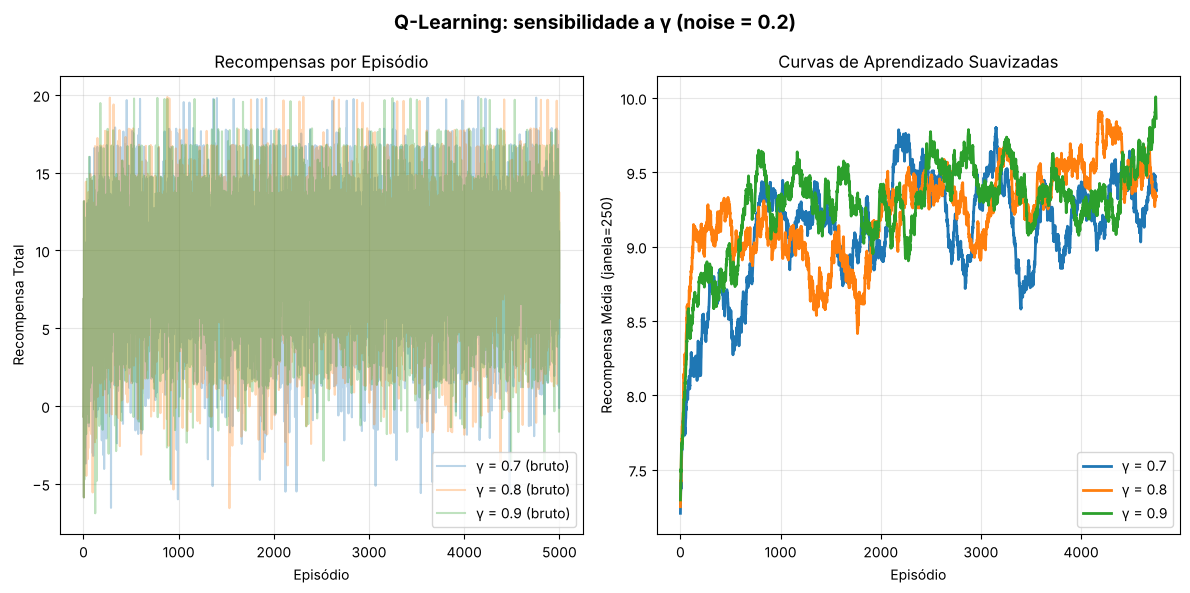

In [17]:
GAMMAS = [0.7, 0.8, 0.9]
RES_G = {}
for g in GAMMAS:
    RES_G[g] = RES['Q-Learning'] if g == GAMMA else treinar(q_learning, build_gridworld(gamma=g, noise=NOISE), g)

plot_learning_curves({f'γ = {g}': RES_G[g]['recompensas'] for g in GAMMAS}, window=WINDOW,
                     title=f"Q-Learning: sensibilidade a γ (noise = {NOISE})")

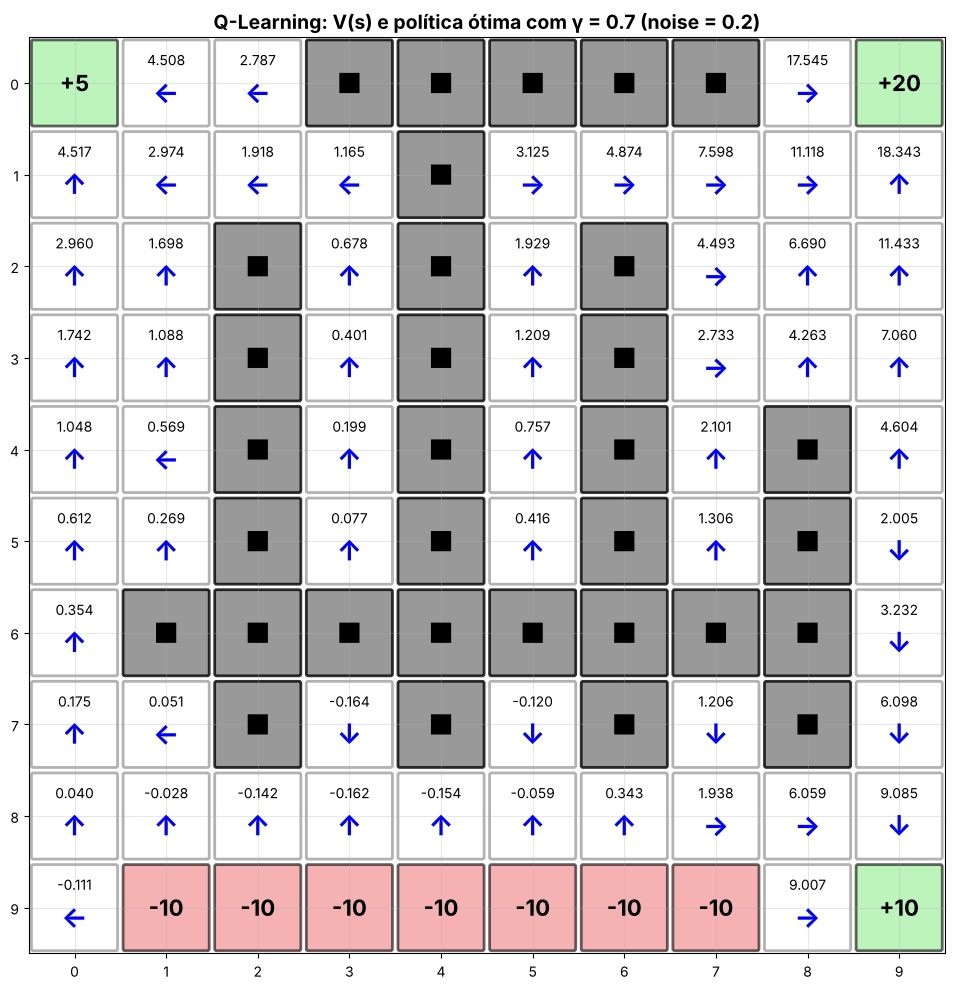

γ = 0.7: mudanças reais vs. γ = 0.9 -> [((6, 9), 1.61), ((8, 5), 0.74)]


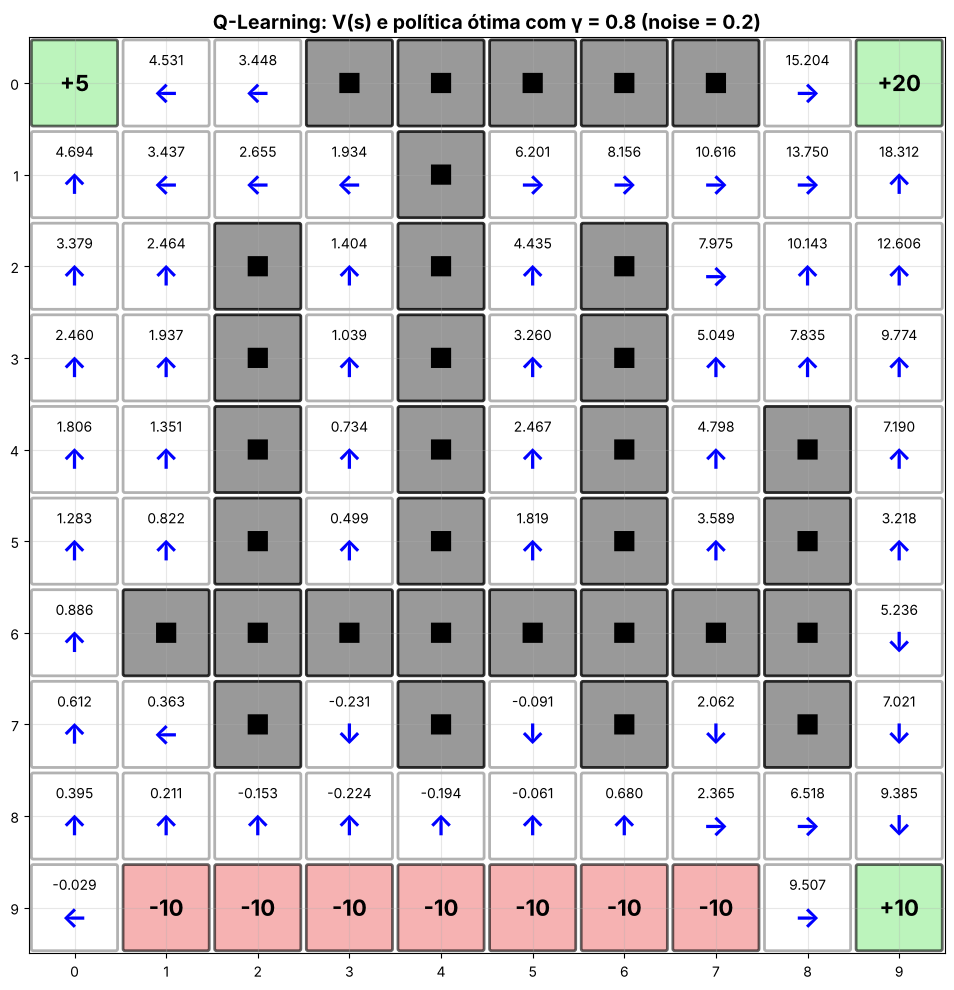

γ = 0.8: mudanças reais vs. γ = 0.9 -> [((6, 9), 0.75), ((8, 5), 0.11)]


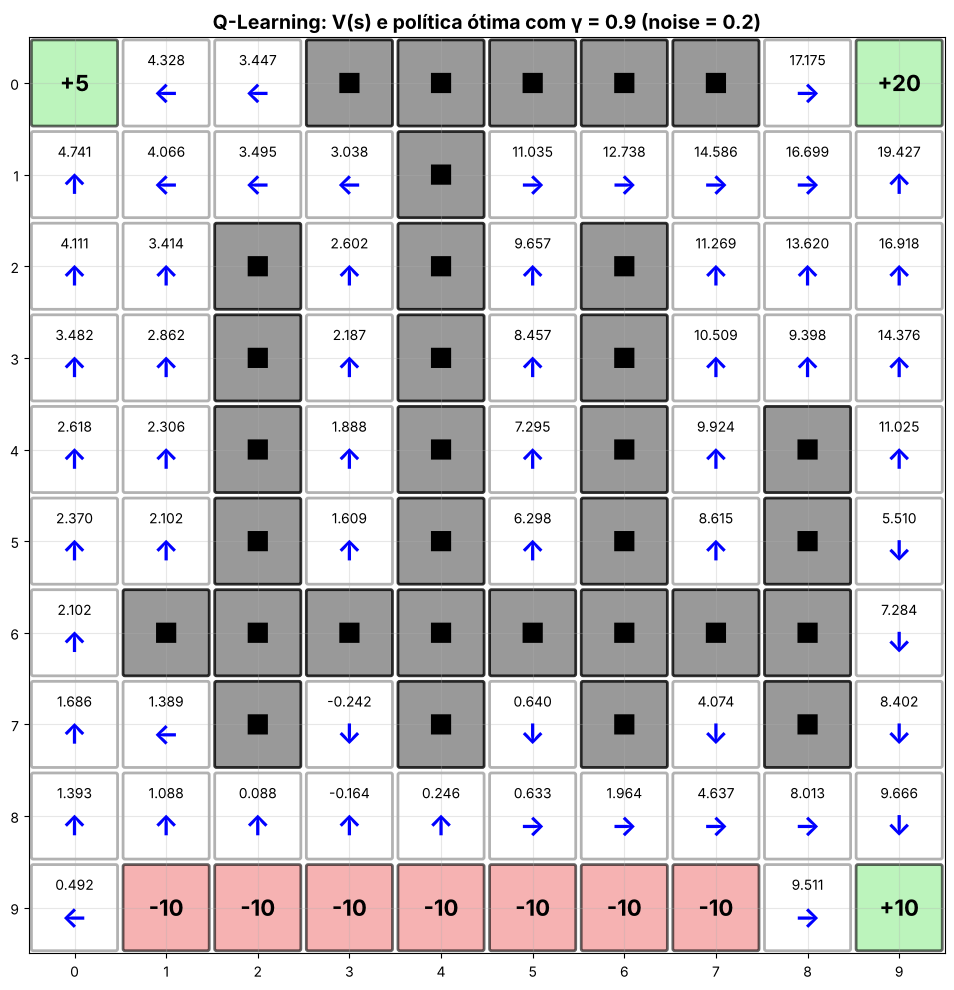

γ = 0.9: mudanças reais vs. γ = 0.9 -> nenhuma


In [18]:
for g in GAMMAS:
    r = RES_G[g]
    visualize_gridworld(r['gw'], values=valores_de_Q(r['Q'], r['gw']), policy=get_greedy_policy(r['Q'], r['gw']),
                        figsize=FIGSIZE, title=f"Q-Learning: V(s) e política ótima com γ = {g} (noise = {NOISE})")
    print(f"γ = {g}: mudanças reais vs. γ = 0.9 -> {mudancas_reais(r, RES_G[0.9]) or 'nenhuma'}")

In [19]:
def tabela_sensibilidade(resultados, rotulo, ref):
    linhas = {}
    for k, r in resultados.items():
        m = avaliar_politica(r['gw'], r['Q'], r['gamma'])
        V_star, Q_star = gabarito(r['gw'], r['gamma'])
        linhas[k] = {'% ações ótimas': m['pct_otimas'], 'perda de valor': m['perda_valor'],
                     'retorno médio (últ. 500)': np.mean(r['recompensas'][-500:]),
                     'mudanças reais vs. ref.': len(mudancas_reais(r, resultados[ref])),
                     'V* médio (exato)': np.mean([V_star[s] for s in Q_star])}
    return pd.DataFrame(linhas).T.rename_axis(rotulo).round(3)


tabela_sensibilidade(RES_G, 'γ', ref=0.9)

,% ações ótimas,perda de valor,retorno médio (últ. 500),mudanças reais vs. ref.,V* médio (exato)
γ,,,,,
0.7,93.103,0.020,9.398,2.0,3.204
0.8,96.552,0.019,9.438,2.0,4.425
0.9,96.552,0.119,9.707,0.0,6.531


## 11. Sensibilidade ao noise (Q-Learning)

O noise controla a **confiabilidade das ações**. Com noise alto, andar rente à fileira de terminais de −10 fica perigoso: um deslize lateral pode ser fatal. Percorrer corredores longos até o +20 também fica mais difícil.

**Como é feito:** para cada noise cria-se um **grid novo** (`noise=n`), em vez de alterar `gw.noise` do grid original, para o valor não vazar para outras células. γ fixo em 0.9, e o caso noise = 0.2 reaproveita o treino da seção 6.

**Hipótese:** com mais noise, as políticas se afastam da linha 9 e dos terminais negativos, e o aprendizado inicial fica mais lento.

> As curvas de retorno de noises diferentes **não medem qualidade** de forma direta, porque o ambiente fica mais difícil quando o noise sobe (o retorno ótimo cai). O que se compara é a forma da curva e a política obtida.

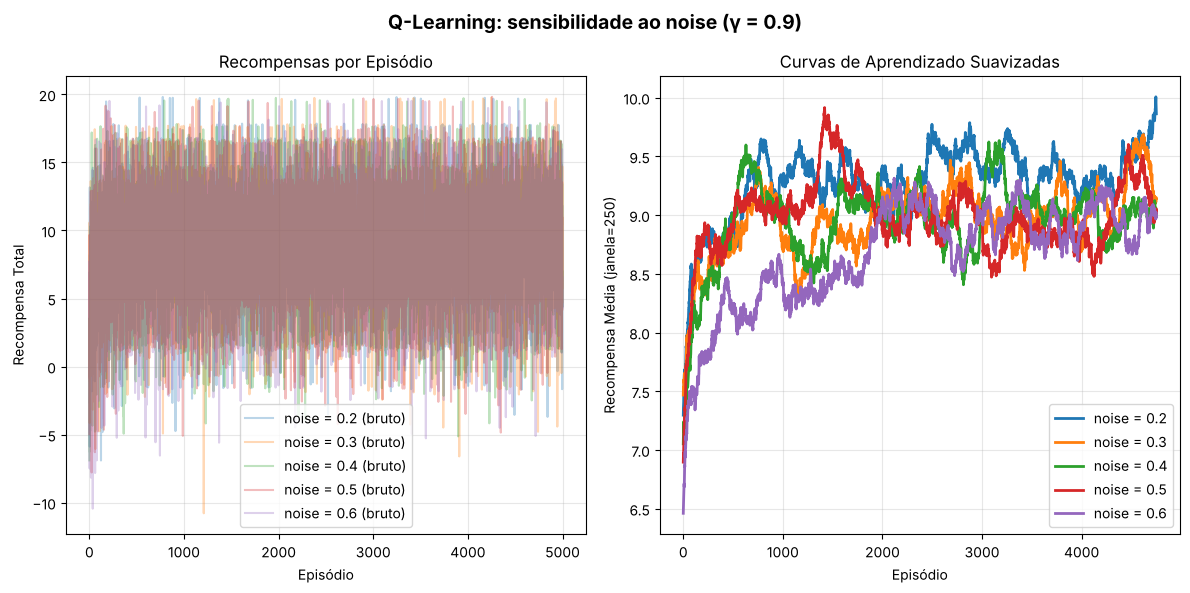

In [20]:
NOISES = [0.2, 0.3, 0.4, 0.5, 0.6]
RES_N = {}
for n in NOISES:
    RES_N[n] = RES['Q-Learning'] if n == NOISE else treinar(q_learning, build_gridworld(gamma=GAMMA, noise=n), GAMMA)

plot_learning_curves({f'noise = {n}': RES_N[n]['recompensas'] for n in NOISES}, window=WINDOW,
                     title=f"Q-Learning: sensibilidade ao noise (γ = {GAMMA})")

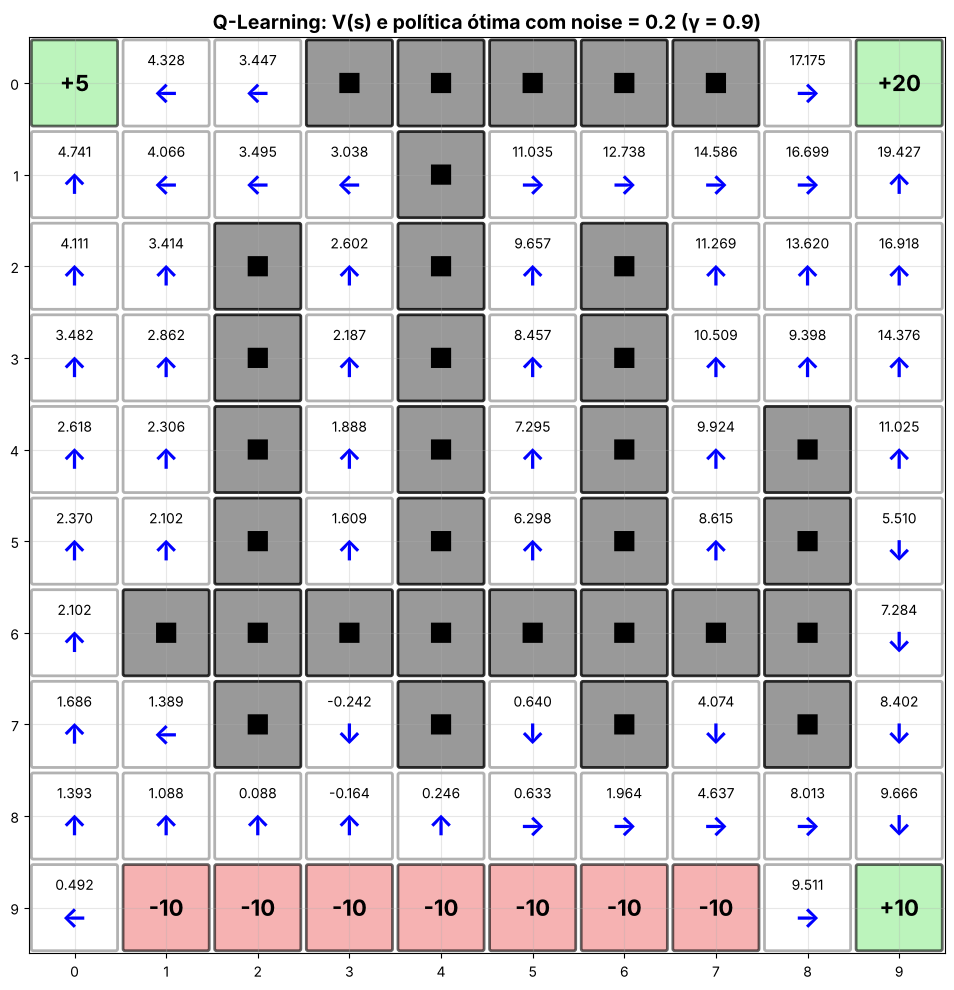

noise = 0.2: mudanças reais vs. noise = 0.2 -> nenhuma


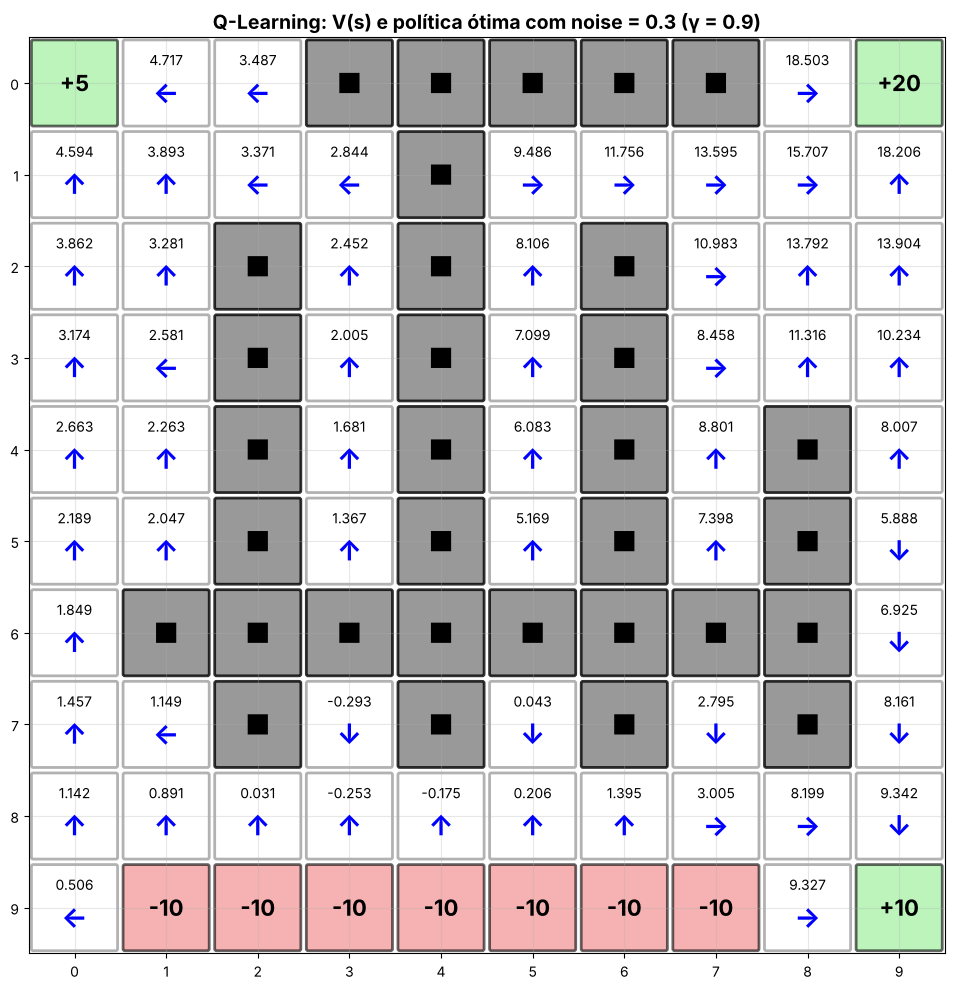

noise = 0.3: mudanças reais vs. noise = 0.2 -> [((8, 5), 0.81), ((8, 6), 0.19)]


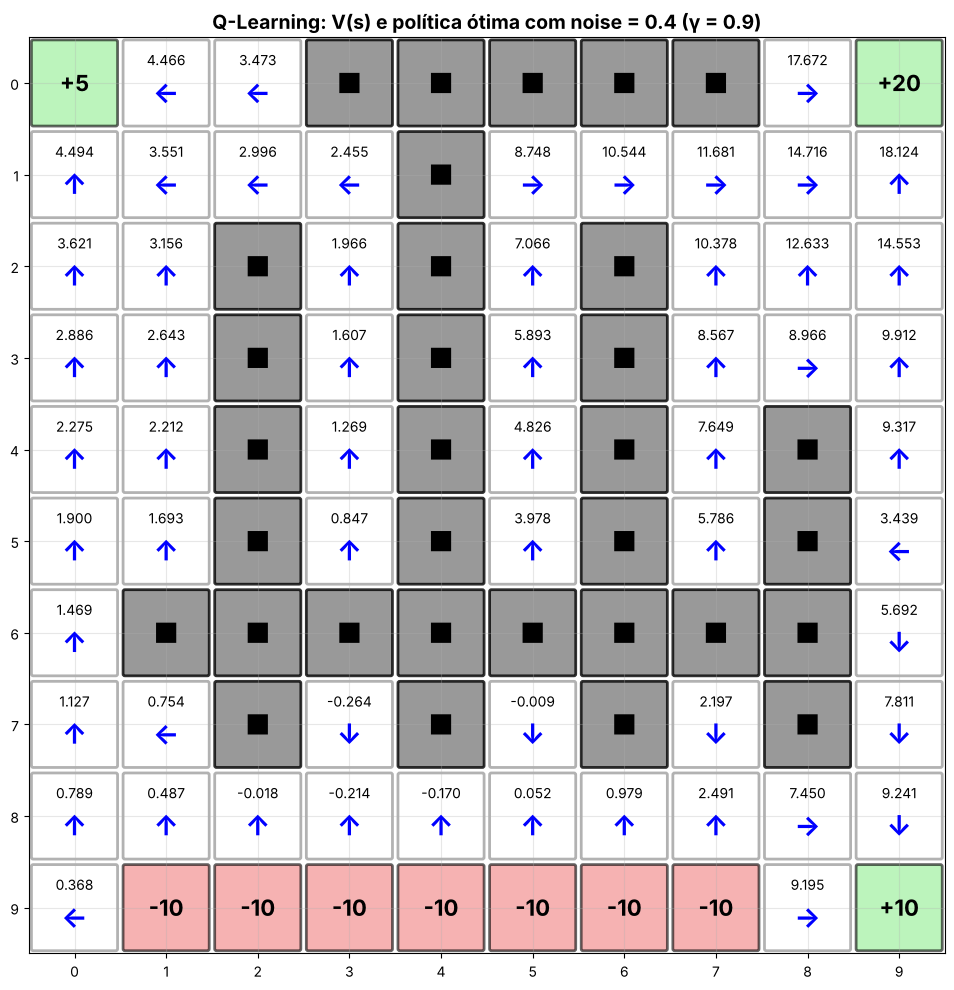

noise = 0.4: mudanças reais vs. noise = 0.2 -> [((8, 5), 1.6), ((8, 6), 1.38), ((8, 7), 0.16)]


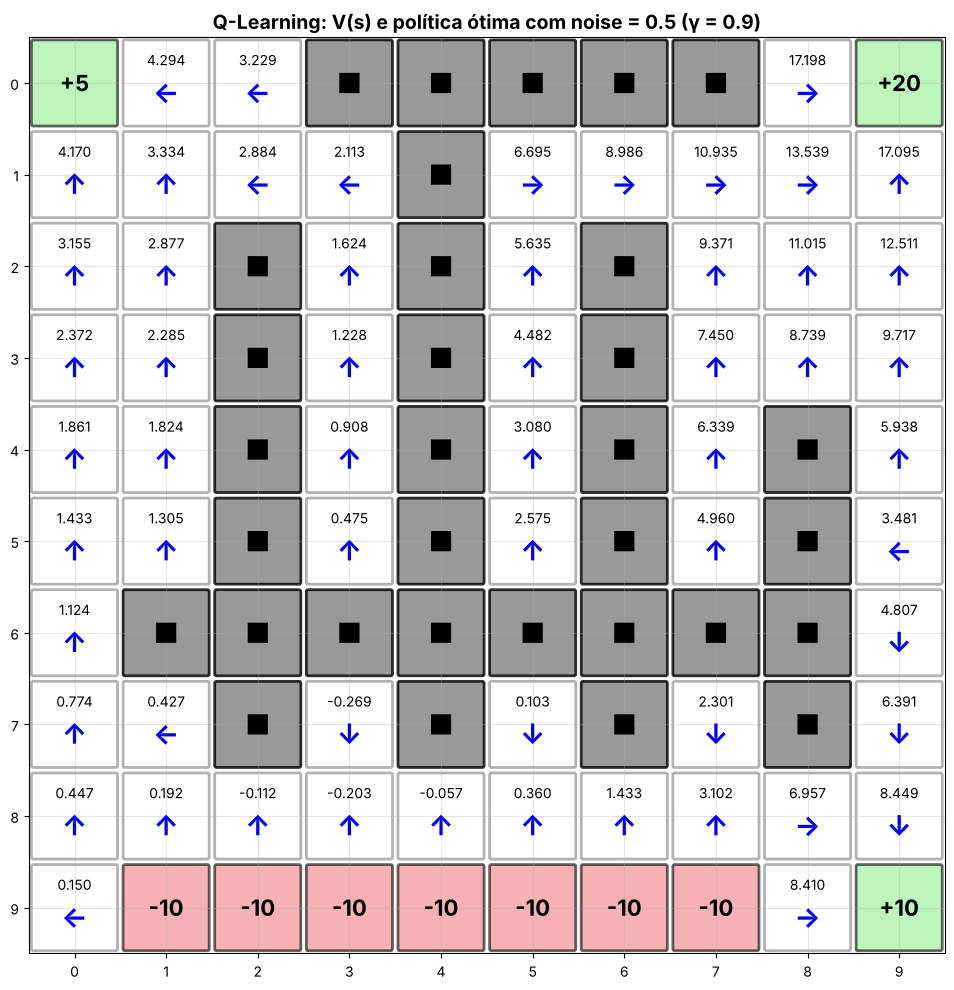

noise = 0.5: mudanças reais vs. noise = 0.2 -> [((6, 9), 0.13), ((8, 5), 2.23), ((8, 6), 2.16), ((8, 7), 1.61)]


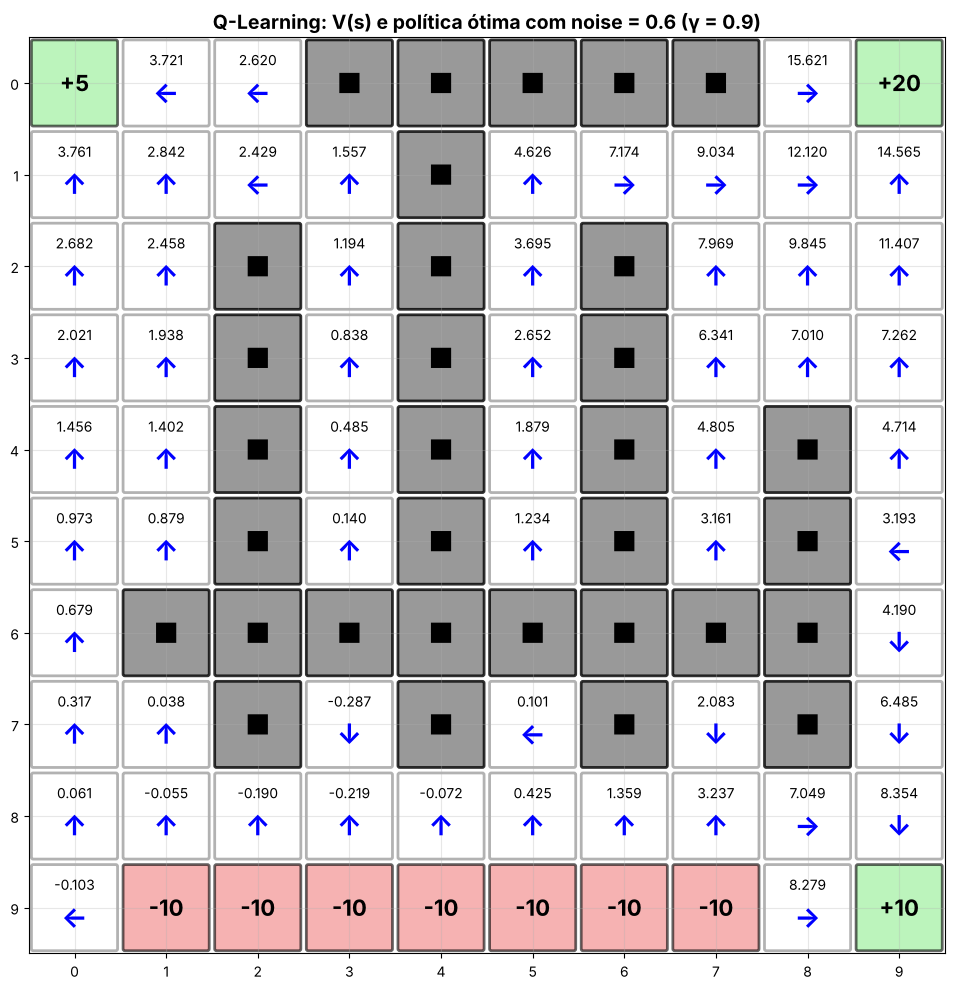

noise = 0.6: mudanças reais vs. noise = 0.2 -> [((0, 8), 0.43), ((1, 3), 0.05), ((1, 5), 0.14), ((3, 8), 0.12), ((6, 9), 0.46), ((8, 5), 2.88), ((8, 6), 2.94), ((8, 7), 2.92)]


In [21]:
for n in NOISES:
    r = RES_N[n]
    visualize_gridworld(r['gw'], values=valores_de_Q(r['Q'], r['gw']), policy=get_greedy_policy(r['Q'], r['gw']),
                        figsize=FIGSIZE, title=f"Q-Learning: V(s) e política ótima com noise = {n} (γ = {GAMMA})")
    print(f"noise = {n}: mudanças reais vs. noise = 0.2 -> {mudancas_reais(r, RES_N[0.2]) or 'nenhuma'}")

In [22]:
tabela_sensibilidade(RES_N, 'noise', ref=0.2)

,% ações ótimas,perda de valor,retorno médio (últ. 500),mudanças reais vs. ref.,V* médio (exato)
noise,,,,,
0.2,96.552,0.119,9.707,0.0,6.531
0.3,91.379,0.128,9.292,2.0,5.903
0.4,94.828,0.051,9.027,3.0,5.252
0.5,98.276,0.019,9.160,4.0,4.556
0.6,93.103,0.062,8.853,8.0,3.806


## 12. Conclusões

Todos os números abaixo vêm das saídas deste notebook, com **as passagens em (8,2) e (8,6) abertas** (58 células livres), 5.000 episódios, 5 seeds, α = 0,1 e ε = 0,1 constante. As comparações usam o **gabarito exato** (Value Iteration) e o retorno de treino como apoio.

**1. Algoritmos (γ = 0,9, noise = 0,2).** O Q-Learning acertou 97% das ações ótimas (96,6%), contra 91% do Expected SARSA e 84% do SARSA. A política trivial "sempre N" acerta 64%, então todos aprenderam algo real. A **perda de valor** conta outra história: 0,119 no Q-Learning, 0,103 no SARSA e 0,099 no Expected SARSA, ou seja, os três ficam próximos, e o Q-Learning acerta mais células mas erra algumas com mais custo. No retorno dos últimos 500 episódios, o Q-Learning teve 9,71, contra 8,99 (Expected SARSA) e 8,79 (SARSA), com desvio entre seeds de 0,44 a 0,53. O Q-Learning superou o SARSA nas 5 seeds e o Expected SARSA em 4 de 5. Isso sugere uma vantagem do Q-Learning **neste ambiente e com estes hiperparâmetros**, mas 5 seeds e uma única configuração não bastam para generalizar. A política vem da média das 5 tabelas Q.

**2. Linha 8 e região inferior.** Com as passagens abertas, a linha 8 é o único caminho entre a esquerda e a direita, e corre colada aos terminais de −10. O V* das 5 células da região inferior fica entre −0,21 e 1,37, muito abaixo das células de cima (até ≈ 19). A política aprendida pelo Q-Learning não atravessa a linha 8 a partir de (8,3) e (8,4): ela aponta para cima nessas células e para baixo em (7,3) e (7,5), de modo que o agente fica nessa região até um escorregão ou a exploração o tirarem de lá. A simulação mostrou que todo episódio da política termina em 2.000 passos.

**3. TD(0).** Com a política gulosa do Q-Learning (sem ajuste), o TD(0) estimou V^π com RMSE de 0,23 a 0,37 por seed (α = 0,05, 20.000 episódios). O V médio nos estados livres foi 6,42 (TD) contra 6,41 (exato) e 6,53 (ótimo, V*). O RMSE médio cai de 7,2 (100 episódios) para 0,23 (10.000) e fica em 0,20 com 30.000: com α constante o TD(0) **oscila ao redor** do valor verdadeiro em vez de convergir. O maior erro da média das 5 seeds em um estado foi 0,68.

**4. Sensibilidade a γ (Q-Learning).** O V* médio cai de 6,53 (γ = 0,9) para 4,43 (0,8) e 3,20 (0,7). A política aprendida acerta 93% a 97% das ações nos três casos. Em relação a γ = 0,9, só **2 células** mudam de forma real, (6,9) e (8,5), em γ = 0,8 (perdas de 0,75 e 0,11) e em γ = 0,7 (1,61 e 0,74). Neste layout, γ entre 0,7 e 0,9 altera mais a **escala dos valores** do que a política.

**5. Sensibilidade ao noise (Q-Learning).** O V* médio cai de 6,53 (0,2) para 3,81 (0,6). O número de células cuja ação ótima de referência passa a perder valor é 0, 2, 3, 4 e 8 para noise = 0,2 / 0,3 / 0,4 / 0,5 / 0,6. As primeiras a mudar, já a partir de 0,3, são (8,5) e (8,6), e depois (8,7), todas na linha 8 colada aos −10. No noise = 0,6 a figura mostra essas células apontando para cima, **para longe da linha 9**, em vez de seguir para a direita como em noise = 0,2. O retorno de treino cai de 9,71 (0,2) para 8,85 (0,6), e a curva de noise = 0,6 sobe mais devagar no início.

**Limitações.** (a) Os módulos não têm decaimento de ε, nem limite de passos por episódio, nem parâmetro de seed: usei ε constante e `np.random.seed` global. (b) Cinco seeds não dão intervalo de confiança; diferenças pequenas entre algoritmos podem ser ruído. (c) O retorno por episódio depende muito do estado inicial sorteado, por isso ele é ruidoso e só apoia a comparação. (d) Os resultados e conclusões das versões anteriores (v1 e a v2 com paredes em (8,2) e (8,6)) **não valem** para este layout. (e) O `plot_value_heatmap` mostra os terminais em branco (comportamento do módulo).